# Does pre-existing β-lactamase capacity predict community resilience?

## The question

For one fixed synthetic community of **57 unique strains**, does greater resistant-carrier abundance **immediately before antibiotic treatment** predict better diversity retention and smaller compositional changes? Does this association change from early treatment to post-treatment recovery?

**What this notebook does**

1. Keeps the same intrinsic growth rate, underlying susceptibility and equal inoculum for each strain.
2. Varies resistant strain count: **0, 1, 5, 10, 20, 30, 40, 57**.
3. Repeats the six intermediate counts using **10 random carrier orders**, keeping intrinsic traits fixed. Counts are nested within an order. Each order may start with any strain; k30 is not forced to be a carrier.
4. Runs each design with antibiotic and with a matched untreated control.
5. Measures carrier biomass immediately before the 4 h antibiotic dose.
6. Calculates Shannon retention and Bray–Curtis dissimilarity at **6, 24, 48 h**, relative to the same community at **4 h**.
7. Plots and quantifies time-specific correlations; repeats them with untreated-adjusted outcomes; reports uncertainty from resampling whole carrier orders.

**Run:** Open in Jupyter and select **Restart Kernel → Run All**. The original uploaded biological model is embedded, so no sibling model files are needed. Dependencies: NumPy, pandas, SciPy, Matplotlib ≥3.7, IPython. Default execution involves up to **124 simulations**. Completed runs are cached for subsequent reruns. Outputs are written to `baseline_resistance_correlation_results` beside the notebook. Figures and results are already included.

**What the x-axis means:** The model has no explicit enzyme concentration. All carriers share a degradation capacity per unit live biomass, so **carrier biomass at 4 h (OD)** is a proxy for β-lactamase capacity. Multiplying it by the model's `vmax` gives the baseline maximum drug-degradation capacity (µg/mL/h). Neither is measured protein abundance, gene abundance or gene expression. This is a synthetic-model investigation, not an analysis of patient metagenomes.


## 1. Define the analysis before looking at results

| Item | Definition |
|---|---|
| Pretreatment baseline | 4 h, immediately before antibiotics are added |
| Early response | 6 h: 2 hours after drug addition |
| End of treatment | 24 h: sample before dilution |
| Recovery endpoint | 48 h: after 1:100 transfer and 24 h drug-free regrowth |
| X | Total carrier biomass at 4 h, in OD |
| Shannon retention | $H(t)/H(4)$; 1 = unchanged, below 1 = lower diversity |
| Bray–Curtis | $rac{1}{2}sum_i |p_i(t)-p_i(4)|$; 0 = identical relative composition, 1 = no overlap |
| Untreated-adjusted Shannon | $[H_T(t)/H_T(4)]/[H_C(t)/H_C(4)]$; 1 = the same retention as the matched control |
| Excess Bray–Curtis | $BC_T(t,4)-BC_C(t,4)$; 0 = equal displacement magnitudes from each arm's own baseline |

T = treated; C = matched untreated. Greater resilience would generally mean **higher Shannon retention and lower Bray–Curtis**, but those are separate properties: equal Shannon values can coexist with very different compositions.

**Hypothesis, not an assumed result:** more baseline carrier biomass may support higher retention and smaller composition shifts. The model could instead show saturation, a threshold or different associations at different times.

Early treatment points describe resistance to disturbance. The 48 h point describes recovery after dilution and fresh nutrients. Excess Bray–Curtis compares *magnitudes* of displacement; it does not subtract compositional vectors or prove causal protection. Direct treated-versus-control dissimilarity and biomass ratios are also exported.

Shannon uses all positive simulated abundances, with natural logs. A completely extinct community has **undefined Shannon and composition**, not a numerical diversity of zero for this analysis. Those cases are reported separately and excluded from correlations requiring those measures.


In [1]:
from pathlib import Path
from dataclasses import replace
from contextlib import contextmanager
import sys, types, hashlib, json, colorsys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from scipy.stats import spearmanr, pearsonr
from IPython.display import display

TRAIT_SEED = 42              # Same intrinsic traits in EVERY scenario.
ASSIGNMENT_SEED = 21000      # Separate random stream for resistance identities.
N_ORDERS = 10
COUNTS = [0, 1, 5, 10, 20, 30, 40, 57]
DOSE = 50.0                 # µg/mL carbenicillin
SAMPLE_HOURS = [6.0, 24.0, 48.0]
BOOTSTRAPS = 1000           # Resample whole assignment orders, not individual rows.
BOOTSTRAP_SEED = 817
RECOMPUTE = False
OUT = Path('baseline_resistance_correlation_results')
CACHE = OUT/'cache'; FIGURES = OUT/'figures'
CACHE.mkdir(parents=True, exist_ok=True); FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':10, 'figure.dpi':100,
                    'axes.spines.top':False, 'axes.spines.right':False})


We use the same synthetic community of 57 strains in every simulation, keeping each strain’s intrinsic traits and starting abundance fixed. We vary the number of resistant strains and repeat the experiment using 10 random strain-selection orders. Within each order, increasing the resistant count adds carriers while preserving those already selected. This lets us examine whether the results depend on both how many strains are resistant and which strains carry resistance.

Each configuration receives antibiotic treatment and a matched untreated control. We measure resistant biomass immediately before treatment and compare it with Shannon diversity retention and Bray–Curtis dissimilarity at 6, 24, and 48 hours. Untreated controls help distinguish antibiotic effects from changes caused by growth and competition. Resistant biomass serves as a proxy for β-lactamase capacity because the model assigns every carrier the same degradation capacity per unit biomass.

## 2. Load the unchanged biological equations

The embedded source is the uploaded `updated_consumer_resource_model/resilience_model.py`. Its source hash is checked for reproducibility.

The only extension is **initialization**: we allow an explicit carrier mask instead of using the original function's single default nested carrier order. The ODEs, resource uptake, constant death, growth-dependent killing, resistance cost, saturating degradation, dilution and extinction rules remain the original functions. The override is restored after each simulation. The source file is not edited.

Carriers pay the original 5% growth cost and are immune to drug killing. Thus intrinsic growth rates stay fixed, while effective growth rates change according to carrier status. No mutation or horizontal gene transfer occurs during a run.

In [2]:
ORIGINAL_MODEL_SOURCE = '"""\nPre-existing resistance and post-antibiotic community recovery\n==============================================================\n\nA minimal model of the barcoded E. coli community experiment: grow the community,\ntreat it with carbenicillin, dilute into fresh drug-free medium, let it recover, and\nmeasure how much of the community came back.\n\nEverything needed is in this one file:\n\n    BASELINE          every parameter, with units\n    run(**changes)    one matched experiment -> all readouts\n    sweep(...)        one parameter over a list of values\n    grid(...)         two parameters over a rectangle\n    check()           sanity checks; run once per session, not on import\n\nA notebook needs nothing but:\n\n    from resilience_model import run, sweep, grid, BASELINE, check\n    r = run(growth_mean=0.2)          # anything not named keeps its baseline value\n    r.metrics                         # one row of readouts\n    df = sweep("n_resistant", [0, 1, 2, 4, 8, 16])\n\nSee README.md for the assumptions, their justification, and the tested ranges.\n\nUnits: time in hours, biomass in OD, drug in ug/ml of carbenicillin.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field, replace\nfrom functools import lru_cache\nfrom pathlib import Path\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.integrate import solve_ivp\n\n__all__ = ["BASELINE", "Params", "run", "sweep", "grid", "check", "Result",\n           "TESTED_RANGES", "SAMPLE_HOURS"]\n\nSAMPLE_HOURS = (4.0, 6.0, 24.0, 48.0)   # when the experiment samples\n\n\n# --------------------------------------------------------------------------- parameters\n@dataclass(frozen=True)\nclass Params:\n    """Every parameter of the model. `BASELINE` is the default instance.\n\n    Drug concentrations are in ug/ml of carbenicillin, so `dose` is the number the\n    protocol specifies and `km` is TEM-1\'s measured Michaelis constant in the same unit.\n    """\n    # --- community -------------------------------------------------------------\n    seed: int = 42                  # fixes every strain trait; change to test robustness\n    n_strains: int = 57             # barcoded library size\n    focal_index: int = 29           # k30, the strain that carries the resistance gene\n\n    # --- growth ----------------------------------------------------------------\n    growth_mean: float = 0.55       # 1/h, mean maximum growth rate across strains\n    growth_cv: float = 0.08         # strain-to-strain spread in maximum growth rate\n    food: float = 1.0               # OD-equivalents of nutrient in fresh medium\n    half_saturation: float = 0.05   # OD-equivalents; Monod constant for nutrient uptake\n    death_rate: float = 0.004       # 1/h, constant death rate (fed or starving)\n\n    # --- resistance ------------------------------------------------------------\n    n_resistant: int = 1            # how many strains carry the gene; 0 = sensitive community\n    focal_multiplier: float = 1.0   # starting biomass of k30 relative to the others (1x or 10x)\n    resistance_cost: float = 0.05   # fractional loss of maximum growth rate for a carrier\n\n    # --- antibiotic ------------------------------------------------------------\n    dose: float = 50.0              # ug/ml carbenicillin added at the start of treatment\n    gamma: float = 2.5              # max killing rate, as a multiple of the cell\'s current growth\n    hill: float = 2.0               # Hill coefficient of the killing response\n    susceptible_ic50: float = 5.0   # ug/ml, median IC50 of the susceptible strains\n    ic50_cv: float = 0.70           # strain-to-strain spread in IC50 (lognormal sd)\n    vmax: float = 10000.0           # ug/ml/h per OD of resistant biomass, at saturation\n    km: float = 5.3                 # ug/ml; TEM-1 Km for carbenicillin (14 uM)\n\n    # --- protocol --------------------------------------------------------------\n    initial_biomass: float = 0.005  # total OD at inoculation, split equally across strains\n    pregrowth_h: float = 4.0        # drug-free growth before treatment\n    treatment_h: float = 20.0       # with drug\n    dilution: float = 100.0         # fold dilution at transfer into fresh medium\n    recovery_h: float = 24.0        # drug-free growth after transfer\n\n    # --- measurement -----------------------------------------------------------\n    cells_per_OD: float = 1e9       # sets the extinction floor at one cell\n    detection_rel: float = 1e-4     # relative abundance below which a barcode is not counted\n\n    # --- numerics --------------------------------------------------------------\n    dt_out: float = 0.1             # output spacing, h (does not affect the solution)\n    rtol: float = 1e-8\n    atol: float = 1e-10\n\n    @property\n    def floor(self) -> float:\n        """Extinction threshold: one cell."""\n        return 1.0 / self.cells_per_OD\n\n\nBASELINE = Params()\n\n\n# --------------------------------------------------------------------------- community\n@lru_cache(maxsize=256)\ndef _traits(seed: int, n: int, growth_mean: float, growth_cv: float,\n            susceptible_ic50: float, ic50_cv: float):\n    """Per-strain maximum growth rate and IC50.\n\n    Strains differ in these two properties and nothing else: they are near-isogenic\n    single-gene deletions of one parent, competing for the same nutrient. Both draws\n    depend only on the seed, so changing any other parameter compares the same strains.\n    """\n    rng = np.random.default_rng(seed)\n    s = np.sqrt(np.log1p(growth_cv ** 2))\n    mu = growth_mean * np.exp(s * rng.standard_normal(n) - s ** 2 / 2)\n    ic50 = susceptible_ic50 * np.exp(ic50_cv * rng.standard_normal(n) - ic50_cv ** 2 / 2)\n    return mu, ic50\n\n\n@lru_cache(maxsize=256)\ndef _carriers(seed: int, n: int, focal_index: int, k: int):\n    """Which strains carry the resistance gene.\n\n    k30 is always first, then others in a fixed order from a dedicated random stream,\n    so the sets are nested: raising k adds carriers without reshuffling the existing\n    ones, and the draw never disturbs the trait sampling.\n    """\n    mask = np.zeros(n, bool)\n    if k <= 0:\n        return mask\n    others = np.array([i for i in range(n) if i != focal_index])\n    order = np.random.default_rng(seed + 991).permutation(others)\n    mask[np.r_[focal_index, order[:k - 1]].astype(int)] = True\n    return mask\n\n\ndef community(p: Params):\n    """Strain traits, carrier mask and starting biomass for one parameter set."""\n    mu, ic50 = _traits(p.seed, p.n_strains, p.growth_mean, p.growth_cv,\n                       p.susceptible_ic50, p.ic50_cv)\n    carrier = _carriers(p.seed, p.n_strains, p.focal_index, p.n_resistant)\n    mu = mu * (1 - p.resistance_cost * carrier)   # the enzyme is expressed constantly, so\n                                                  # its cost is a constant growth penalty\n    n0 = np.full(p.n_strains, p.initial_biomass / p.n_strains)\n    n0[p.focal_index] *= p.focal_multiplier\n    return mu, ic50, carrier, n0\n\n\n# --------------------------------------------------------------------------- dynamics\ndef _rates(N, R, a, mu, ic50, carrier, p: Params):\n    """Per-strain growth and killing, nutrient draw-down, and drug degradation."""\n    R = max(R, 0.0)\n    a = max(a, 0.0)\n    g = mu * R / (p.half_saturation + R)              # Monod growth on the shared nutrient\n    if a > 0.0:\n        x = (a / ic50) ** p.hill\n        kill = p.gamma * (x / (1.0 + x)) * g          # beta-lactam killing needs growth\n        kill = np.where(carrier, 0.0, kill)           # carriers are immune at these doses\n    else:\n        kill = np.zeros_like(g)\n    dR = -float(np.sum(N * g))                        # 1 OD of biomass consumes 1 unit of food\n    resistant_biomass = float(np.sum(N[carrier]))\n    da = -p.vmax * resistant_biomass * a / (p.km + a) # saturating degradation by live carriers\n    return g, kill, dR, da\n\n\ndef _segment(N0, R0, a0, t0, t1, mu, ic50, carrier, p: Params, alive):\n    """Integrate one phase, stopping whenever a strain crosses the one-cell floor.\n\n    Biomass is integrated in log space so that abundances spanning many orders of\n    magnitude stay accurate; a strain that reaches one cell is removed for good.\n    """\n    floor_log = np.log(p.floor)\n    grid_t = np.arange(t0, t1 + p.dt_out / 2, p.dt_out)\n    ts, Ns, Rs, as_, deaths = [], [], [], [], []\n    death_total = 0.0\n    N, R, a = N0.copy(), R0, a0\n\n    while t0 < t1 - 1e-12:\n        idx = np.flatnonzero(alive)\n        if idx.size == 0:\n            te = grid_t[(grid_t >= t0) & (grid_t <= t1)]\n            for t in te:\n                ts.append(t); Ns.append(N.copy()); Rs.append(R); as_.append(a)\n                deaths.append(death_total)\n            break\n\n        def rhs(t, y):\n            Nl = np.zeros_like(N)\n            Nl[idx] = np.exp(y[:idx.size])\n            g, kill, dR, da = _rates(Nl, y[-3], y[-2], mu, ic50, carrier, p)\n            dlog = g[idx] - p.death_rate - kill[idx]\n            dloss = float(np.sum(Nl * (p.death_rate + kill)))\n            return np.r_[dlog, dR, da, dloss]\n\n        def make_event(j):\n            def ev(t, y):\n                return y[j] - floor_log\n            ev.terminal = True\n            ev.direction = -1\n            return ev\n\n        y0 = np.r_[np.log(np.maximum(N[idx], p.floor * 1e-3)), R, a, death_total]\n        te = np.minimum(grid_t[(grid_t >= t0) & (grid_t <= t1)], t1)\n        sol = solve_ivp(rhs, (t0, t1), y0, method="LSODA", t_eval=te,\n                        events=[make_event(j) for j in range(idx.size)],\n                        rtol=p.rtol, atol=p.atol, dense_output=False)\n        if not sol.success:\n            raise RuntimeError(sol.message)\n\n        for k, t in enumerate(sol.t):\n            Nk = np.zeros_like(N)\n            Nk[idx] = np.exp(sol.y[:idx.size, k])\n            ts.append(float(t)); Ns.append(Nk); Rs.append(float(sol.y[-3, k]))\n            as_.append(float(sol.y[-2, k])); deaths.append(float(sol.y[-1, k]))\n\n        if sol.status == 1:                                  # a strain hit the floor\n            t0 = float(sol.t_events[[len(e) > 0 for e in sol.t_events].index(True)][0])\n            yend = np.concatenate([e for e in sol.y_events if len(e)])[0]\n            N = np.zeros_like(N); N[idx] = np.exp(yend[:idx.size])\n            R, a, death_total = float(yend[-3]), float(yend[-2]), float(yend[-1])\n            hit = idx[np.isclose(yend[:idx.size], floor_log, atol=1e-9)]\n            if hit.size == 0:\n                hit = idx[[int(np.argmin(yend[:idx.size]))]]\n            death_total += float(np.sum(N[hit]))             # the last cell is accounted for\n            alive[hit] = False\n            N[hit] = 0.0\n        else:\n            t0 = t1\n            N = Ns[-1].copy() if Ns else N\n            R, a, death_total = Rs[-1], as_[-1], deaths[-1]\n\n    return (np.array(ts), np.array(Ns), np.array(Rs), np.array(as_),\n            np.array(deaths), N, R, a, death_total)\n\n\ndef simulate(p: Params) -> dict:\n    """Pre-growth -> treatment -> 1:dilution transfer -> recovery."""\n    mu, ic50, carrier, n0 = community(p)\n    alive = n0 > p.floor\n    t_treat = p.pregrowth_h\n    t_transfer = p.pregrowth_h + p.treatment_h\n    t_end = t_transfer + p.recovery_h\n\n    T, NN, RR, AA, DD = [], [], [], [], []\n    removed = 0.0\n\n    # phase 1: drug-free pre-growth\n    ts, Ns, Rs, as_, dd, N, R, a, death = _segment(\n        n0, p.food, 0.0, 0.0, t_treat, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_); DD += list(dd)\n\n    # phase 2: drug added\n    a = p.dose\n    ts, Ns, Rs, as_, dd, N, R, a, death2 = _segment(\n        N, R, a, t_treat, t_transfer, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death2\n\n    # transfer: 1:dilution into fresh drug-free medium\n    pre_transfer = N.copy()\n    removed += R          # the spent medium, with whatever nutrient is left in it, is discarded\n    N = N / p.dilution\n    removed += float(np.sum(pre_transfer) - np.sum(N))\n    gone = (N < p.floor) & alive\n    removed += float(np.sum(N[gone]))\n    N[gone] = 0.0\n    alive = alive & ~gone\n    post_transfer = N.copy()\n\n    # phase 3: recovery in fresh medium\n    ts, Ns, Rs, as_, dd, N, R, a, death3 = _segment(\n        N, p.food, 0.0, t_transfer, t_end, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death3\n\n    T = np.array(T); NN = np.array(NN)\n    # mass balance: food supplied = biomass standing + biomass dead + biomass discarded\n    supplied = p.food * 2 + float(np.sum(n0))      # fresh medium twice, plus the inoculum\n    standing = float(np.sum(NN[-1])) + float(RR[-1])\n    budget_error = standing + death + removed - supplied\n\n    return dict(params=p, t=T, N=NN, R=np.array(RR), a=np.array(AA),\n                carrier=carrier, mu=mu, ic50=ic50, t_transfer=t_transfer,\n                pre_transfer=pre_transfer, post_transfer=post_transfer,\n                budget_error=budget_error)\n\n\n# --------------------------------------------------------------------------- readouts\ndef snapshot(sim: dict, hour: float) -> np.ndarray:\n    """Absolute abundance of every strain at a sampling time.\n\n    The stored point at the transfer time is the end-of-treatment culture, i.e. the\n    24 h sample taken before the community is diluted.\n    """\n    t = sim["t"]\n    hit = np.flatnonzero(np.isclose(t, hour, atol=1e-7))\n    return sim["N"][hit[0] if hit.size else int(np.argmin(np.abs(t - hour)))]\n\n\ndef detected(x: np.ndarray, p: Params) -> np.ndarray:\n    """Abundances with strains below the sequencing detection limit set to zero."""\n    tot = x.sum()\n    if tot <= 0:\n        return np.zeros_like(x)\n    return np.where(x / tot >= p.detection_rel, x, 0.0)\n\n\ndef shannon(x: np.ndarray) -> float:\n    """H = -sum p ln p, as reported in the manuscript."""\n    s = x.sum()\n    if s <= 0:\n        return 0.0\n    q = x[x > 0] / s\n    return float(-(q * np.log(q)).sum())\n\n\ndef richness(x: np.ndarray) -> int:\n    return int((x > 0).sum())\n\n\ndef bray_curtis(x: np.ndarray, y: np.ndarray) -> float:\n    px = x / x.sum() if x.sum() > 0 else x\n    py = y / y.sum() if y.sum() > 0 else y\n    return float(np.abs(px - py).sum() / max((px + py).sum(), 1e-300))\n\n\n@dataclass\nclass Result:\n    """One matched experiment: resistant and sensitive communities, treated and not."""\n    params: Params\n    runs: dict[tuple[str, bool], dict]      # (community, treated) -> simulation\n    metrics: pd.Series                      # the readouts, one row\n    timeseries: pd.DataFrame                # per-strain abundance at the sampling hours\n    protection: pd.Series                   # per-strain protection score at 24 h\n\n    @property\n    def treated(self) -> dict:\n        return self.runs[("resistant", True)]\n\n    @property\n    def control(self) -> dict:\n        return self.runs[("resistant", False)]\n\n\ndef _metrics(runs, p: Params) -> pd.Series:\n    carrier = runs[("resistant", True)]["carrier"]\n    prot = ~carrier                                  # members without the gene\n\n    def at(key, hour):\n        return detected(snapshot(runs[key], hour), p)\n\n    t48 = {k: at(k, 48.0) for k in runs}\n    xt, xc = t48[("resistant", True)], t48[("resistant", False)]\n    st, sc = t48[("sensitive", True)], t48[("sensitive", False)]\n\n    def ratio(num, den):\n        return float(num / den) if den > 0 else np.nan\n\n    return pd.Series(dict(\n        # --- manuscript readouts, whole community --------------------------------\n        biomass_treated=float(xt.sum()), biomass_control=float(xc.sum()),\n        biomass_resilience=ratio(xt.sum(), xc.sum()),\n        shannon_treated=shannon(xt), shannon_control=shannon(xc),\n        shannon_resilience=ratio(shannon(xt), shannon(xc)),\n        richness_treated=richness(xt), richness_control=richness(xc),\n        compositional_resilience=1 - bray_curtis(xt, xc),\n        # --- the resistant member ------------------------------------------------\n        resistant_share=ratio(xt[carrier].sum(), xt.sum()),\n        resistant_biomass=float(xt[carrier].sum()),\n        n_resistant=int(carrier.sum()),\n        resistant_fraction=float(carrier.sum() / p.n_strains),\n        # --- the members the resistance is protecting ----------------------------\n        protected_shannon=shannon(xt[prot]), protected_shannon_control=shannon(xc[prot]),\n        protected_shannon_ratio=ratio(shannon(xt[prot]), shannon(xc[prot])),\n        protected_richness=richness(xt[prot]), protected_richness_control=richness(xc[prot]),\n        protected_biomass_ratio=ratio(xt[prot].sum(), xc[prot].sum()),\n        # --- the matched all-sensitive community ---------------------------------\n        sensitive_biomass_resilience=ratio(st.sum(), sc.sum()),\n        sensitive_shannon_treated=shannon(st), sensitive_shannon_control=shannon(sc),\n        sensitive_richness_treated=richness(st),\n        # --- diagnostics ---------------------------------------------------------\n        drug_at_24h=float(runs[("resistant", True)]["a"][\n            int(np.argmin(np.abs(runs[("resistant", True)]["t"] - 24.0)))]),\n        budget_error=max(abs(r["budget_error"]) for r in runs.values()),\n    ))\n\n\ndef _timeseries(runs, p: Params) -> pd.DataFrame:\n    rows = []\n    for (comm, trt), sim in runs.items():\n        for h in SAMPLE_HOURS:\n            x = snapshot(sim, h)\n            tot = x.sum()\n            for i in range(p.n_strains):\n                rows.append(dict(community=comm, treated=trt, hour=h, strain=f"k{i + 1:02d}",\n                                 carrier=bool(sim["carrier"][i]), absolute=float(x[i]),\n                                 relative=float(x[i] / tot) if tot > 0 else 0.0))\n    return pd.DataFrame(rows)\n\n\ndef _protection(runs, p: Params) -> pd.Series:\n    """log2[(treated/untreated with resistance) / (treated/untreated without)] at 24 h.\n\n    A one-cell pseudocount keeps strains that were removed from dividing by zero.\n    """\n    fl = p.floor\n\n    def x(key):\n        return snapshot(runs[key], 24.0) + fl\n\n    score = np.log2((x(("resistant", True)) / x(("resistant", False))) /\n                    (x(("sensitive", True)) / x(("sensitive", False))))\n    carrier = runs[("resistant", True)]["carrier"]\n    names = np.array([f"k{i + 1:02d}" for i in range(p.n_strains)])\n    return pd.Series(score[~carrier], index=names[~carrier], name="log2_protection")\n\n\n@lru_cache(maxsize=512)\ndef _cached_sim(p: Params) -> dict:\n    return simulate(p)\n\n\ndef run(params: Params | None = None, **changes: Any) -> Result:\n    """Run one matched experiment and return every readout.\n\n    Anything not named keeps its baseline value::\n\n        run()                       # the baseline experiment\n        run(growth_mean=0.2)        # slower community, everything else unchanged\n        run(dose=70, n_resistant=4)\n\n    The four runs are the manuscript\'s design: resistant and all-sensitive communities,\n    each treated and untreated. The untreated runs carry no drug, so they are cached and\n    reused across a sweep.\n    """\n    p = replace(params or BASELINE, **changes)\n    if p.n_resistant <= 0:\n        raise ValueError("n_resistant must be at least 1; the all-sensitive community "\n                         "is built automatically as the matched control")\n    sensitive = replace(p, n_resistant=0)\n    runs = {\n        ("resistant", True): _cached_sim(p),\n        ("resistant", False): _cached_sim(replace(p, dose=0.0)),\n        ("sensitive", True): _cached_sim(sensitive),\n        ("sensitive", False): _cached_sim(replace(sensitive, dose=0.0)),\n    }\n    return Result(params=p, runs=runs, metrics=_metrics(runs, p),\n                  timeseries=_timeseries(runs, p), protection=_protection(runs, p))\n\n\n# --------------------------------------------------------------------------- sweeps\ndef _row(changes: dict) -> pd.Series:\n    """One sweep row: the parameters that were changed, then every readout.\n\n    A changed parameter that is also a readout name (`n_resistant`, say) is kept only\n    once, so the row index stays unique.\n    """\n    r = run(**changes)\n    extra = pd.Series({"protection_median": float(r.protection.median()),\n                       "protection_min": float(r.protection.min()),\n                       "protection_max": float(r.protection.max())})\n    head = pd.Series({k: v for k, v in changes.items()\n                      if k not in r.metrics.index and k not in extra.index})\n    return pd.concat([head, r.metrics, extra])\n\n\ndef sweep(parameter: str, values, cache: str | None = None,\n          recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary one parameter over a list of values; everything else stays at baseline.\n\n        sweep("n_resistant", [1, 2, 4, 8, 16], vmax=500)\n\n    `cache` names a CSV: the sweep is computed once and reloaded afterwards. Delete the\n    file, or pass `recompute=True`, to run it again.\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({parameter: v, **fixed}) for v in values])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\ndef grid(p1: str, v1, p2: str, v2, cache: str | None = None,\n         recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary two parameters over a rectangle, for a heatmap.\n\n        grid("gamma", [1, 2, 4], "vmax", [100, 1000], cache="panelC.csv")\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({p1: a, p2: b, **fixed}) for a in v1 for b in v2])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\n# --------------------------------------------------------------------------- checks\nTESTED_RANGES = {\n    # parameter: (low, high) - the span over which the model has been exercised and\n    # behaves sensibly. Outside these the solver may struggle or the biology stops\n    # making sense; see README.md.\n    "growth_mean": (0.02, 1.8),\n    "growth_cv": (0.0, 0.6),\n    "food": (0.2, 5.0),\n    "half_saturation": (0.01, 0.5),\n    "death_rate": (0.0005, 0.02),\n    "n_resistant": (1, 57),\n    "focal_multiplier": (1.0, 30.0),\n    "resistance_cost": (0.0, 0.5),\n    "dose": (5.0, 500.0),\n    "gamma": (0.3, 30.0),\n    "hill": (1.0, 4.0),\n    "susceptible_ic50": (1.0, 20.0),\n    "ic50_cv": (0.1, 1.2),\n    "vmax": (10.0, 1e5),\n    "km": (0.5, 50.0),\n    "initial_biomass": (1e-4, 0.05),\n    "dilution": (10.0, 1000.0),\n}\n\n\ndef check(verbose: bool = True) -> pd.DataFrame:\n    """Sanity checks on the model\'s behaviour. Run once per session, not on import."""\n    rows = []\n\n    def add(name, ok, detail):\n        rows.append(dict(check=name, passed=bool(ok), detail=detail))\n\n    base = run()\n\n    # 1. mass balance\n    worst = base.metrics.budget_error\n    add("Mass balance closes: food supplied = biomass + dead + discarded",\n        worst < 1e-6, f"max |error| = {worst:.1e}")\n\n    # 2. no negative state\n    mn = min(min(r["N"].min(), r["R"].min(), r["a"].min()) for r in base.runs.values())\n    add("No negative biomass, nutrient or drug", mn > -1e-8, f"min = {mn:.1e}")\n\n    # 3. zero dose is the untreated control\n    z = run(dose=0.0)\n    d = float(np.max(np.abs(snapshot(z.treated, 48.0) - snapshot(z.control, 48.0))))\n    add("Dose 0 reproduces the untreated control exactly", d < 1e-12, f"max difference = {d:.1e}")\n\n    # 4. no resistance -> resistant and sensitive communities are identical\n    one = run(n_resistant=1, resistance_cost=0.0, vmax=0.0)\n    a1 = snapshot(one.runs[("resistant", True)], 48.0)\n    a2 = snapshot(one.runs[("sensitive", True)], 48.0)\n    d = float(np.max(np.abs(a1 - a2)))\n    add("A carrier that neither degrades nor pays a cost still differs only by its immunity",\n        a1[one.params.focal_index] >= a2[one.params.focal_index] - 1e-12,\n        f"max difference across strains = {d:.1e} (k30 immune, so it can only do better)")\n\n    # 5. killing needs growth\n    stat = run(pregrowth_h=40.0)\n    h = stat.params.pregrowth_h + stat.params.treatment_h\n    ratio = snapshot(stat.runs[("sensitive", True)], h).sum() / \\\n        snapshot(stat.runs[("sensitive", False)], h).sum()\n    add("A drug added in stationary phase kills almost nobody",\n        ratio > 0.95, f"treated/untreated biomass = {ratio:.4f}")\n\n    # 6. the transfer is an exact split\n    c = base.control\n    pre, post = c["pre_transfer"], c["post_transfer"]\n    keep = pre / base.params.dilution >= base.params.floor\n    add("The transfer is an exact 1:dilution split of the survivors",\n        np.allclose(post[keep], pre[keep] / base.params.dilution, rtol=1e-10) and\n        np.all(post[~keep] == 0.0),\n        f"1:{base.params.dilution:g}; {int((~keep).sum())} strains fell below one cell "\n        f"and were removed")\n\n    # 7. extinction is irreversible\n    bad = 0\n    for r in base.runs.values():\n        ever_zero = (r["N"] <= 0).any(axis=0)\n        for j in np.flatnonzero(ever_zero):\n            first = int(np.argmax(r["N"][:, j] <= 0))\n            if np.any(r["N"][first:, j] > 0):\n                bad += 1\n    add("A strain removed at the one-cell floor never returns", bad == 0,\n        f"{bad} strains reappeared")\n\n    # 8. carriers are immune\n    hard = run(dose=500.0, gamma=20.0, vmax=0.0)\n    x = snapshot(hard.treated, 48.0)\n    add("Resistant strains survive a dose that removes the susceptible ones",\n        x[hard.runs[("resistant", True)]["carrier"]].sum() > 0,\n        f"k30 biomass {x[hard.params.focal_index]:.3g} OD, "\n        f"susceptible richness {richness(detected(x, hard.params)) - 1}")\n\n    # 9. more resistant biomass clears the drug faster\n    slow = [run(n_resistant=k, vmax=20.0).metrics.drug_at_24h for k in (1, 8)]\n    add("More resistant biomass leaves less drug behind", slow[1] <= slow[0] + 1e-9,\n        f"drug at 24 h: 1 carrier {slow[0]:.3g}, 8 carriers {slow[1]:.3g} ug/ml")\n\n    # 10. saturating degradation makes clearance time scale with dose\n    # 10. degradation saturates: well above Km the removal rate stops tracking the dose.\n    # This is what keeps the dose dependence in the model; with first-order degradation\n    # the rate would be proportional to the dose and the two ratios below would match.\n    p0 = BASELINE\n    mu_, ic50_, carrier_, n0_ = community(p0)\n    N_ = np.where(carrier_, 0.01, 0.0)                 # a fixed amount of resistant biomass\n\n    def removal(a):\n        return -_rates(N_, p0.food, a, mu_, ic50_, carrier_, p0)[3]\n    hi = removal(10 * p0.km) / removal(5 * p0.km)      # both well above Km -> nearly flat\n    lo = removal(0.1 * p0.km) / removal(0.05 * p0.km)  # both well below Km -> nearly linear\n    add("Degradation saturates above Km and is first-order below it",\n        hi < 1.2 and lo > 1.8,\n        f"doubling the drug multiplies the removal rate by {hi:.2f} above Km "\n        f"and {lo:.2f} below it (first-order everywhere would give 2.00)")\n\n    # 11. resilience of an untreated run against itself is 1\n    add("Untreated against untreated gives resilience 1",\n        abs(1 - bray_curtis(snapshot(c, 48.0), snapshot(c, 48.0)) - 1.0) < 1e-12,\n        "compositional resilience = 1.000")\n\n    # 12. It is degradation that rescues the community, not the mere presence of a\n    # surviving resistant strain. A carrier that degrades nothing still competes for\n    # nutrient, which slows everyone\'s growth and therefore slows killing, so a small\n    # positive protection score remains. That residual must be far weaker than enzymatic\n    # degradation, and it must not rescue the susceptible members.\n    no_enz = run(vmax=0.0)\n    with_enz = base\n    add("Degradation, not the survival of a resistant strain, rescues the community",\n        float(with_enz.protection.median()) > 2 * float(no_enz.protection.median()) and\n        with_enz.metrics.protected_richness > no_enz.metrics.protected_richness + 10,\n        f"median protection {with_enz.protection.median():.1f} with the enzyme vs "\n        f"{no_enz.protection.median():.1f} without; susceptible survivors "\n        f"{with_enz.metrics.protected_richness:.0f} vs {no_enz.metrics.protected_richness:.0f} of 56")\n\n    # 13. Shannon cannot exceed ln(number of strains)\n    worstH = max(shannon(snapshot(r, 4.0)) for r in base.runs.values())\n    cap = np.log(base.params.n_strains)\n    add("Shannon diversity stays below ln(n_strains)", worstH <= cap + 1e-9,\n        f"max H = {worstH:.3f}, ln({base.params.n_strains}) = {cap:.3f}")\n\n    # 14. solver convergence\n    tight = run(rtol=1e-10, atol=1e-12)\n    rel = float(np.max(np.abs(snapshot(base.treated, 48.0) - snapshot(tight.treated, 48.0))) /\n                max(snapshot(tight.treated, 48.0).max(), 1e-300))\n    add("Tighter solver tolerances give the same answer", rel < 1e-4,\n        f"max relative difference = {rel:.1e}")\n\n    # 15. results are not an artefact of one seed\n    direction = [run(seed=s).metrics.protected_shannon_ratio >=\n                 run(seed=s, vmax=0.0).metrics.protected_shannon_ratio for s in (1, 7, 42, 99)]\n    add("Degradation helps the susceptible members for every seed tested",\n        all(direction), f"{sum(direction)}/4 seeds")\n\n    df = pd.DataFrame(rows)\n    if verbose:\n        with pd.option_context("display.width", 200, "display.max_colwidth", 95):\n            print(df.to_string(index=False))\n        print(f"\\n{int(df.passed.sum())}/{len(df)} checks passed")\n    return df\n\n\nif __name__ == "__main__":\n    check()\n'
MODEL_SHA256 = 'a95f4c4c0490fbe35bced5985380cd43f4c38bffd0645a8d9976c700831cdeeb'
assert hashlib.sha256(ORIGINAL_MODEL_SOURCE.encode()).hexdigest() == MODEL_SHA256
model = types.ModuleType('original_model_for_correlations')
model.__file__ = 'embedded_original_resilience_model.py'
sys.modules[model.__name__] = model
exec(compile(ORIGINAL_MODEL_SOURCE, model.__file__, 'exec'), model.__dict__)
original_community = model.community
BASE = replace(model.BASELINE, seed=TRAIT_SEED, dose=DOSE, focal_multiplier=1.0)
assert BASE.n_strains == 57
assert 0 in COUNTS and 57 in COUNTS and len(set(COUNTS))==len(COUNTS)
assert all(isinstance(k,int) and 0<=k<=57 for k in COUNTS)
assert N_ORDERS >= 3
assert SAMPLE_HOURS == [6.0,24.0,48.0]  # Labels assume the original 4/24/48 h protocol.
assert (BASE.pregrowth_h,BASE.treatment_h,BASE.recovery_h,BASE.dilution)==(4.,20.,24.,100.)
NAMES = [f'k{i:02d}' for i in range(1,58)]
INTRINSIC, IC50, _, N0 = original_community(replace(BASE,n_resistant=0))
TRAITS = pd.DataFrame({'strain':NAMES,'intrinsic_mu_per_h':INTRINSIC,
                       'underlying_ic50_ug_ml':IC50,'initial_biomass_OD':N0})
TRAITS.to_csv(OUT/'fixed_strain_traits.csv',index=False)
display(TRAITS.round(6))

@contextmanager
def assigned_carriers(mask):
    mask = np.asarray(mask,bool).copy()
    assert mask.shape == (57,)
    previous = model.community
    def initialize(p):
        # Only resistance assignment changes; no trait redrawing or inoculum multiplier.
        assert p.seed==BASE.seed and p.n_strains==57 and p.focal_multiplier==1
        assert p.n_resistant==int(mask.sum())
        mu = INTRINSIC*(1-p.resistance_cost*mask)
        return mu.copy(),IC50.copy(),mask.copy(),N0.copy()
    model.community = initialize
    try: yield
    finally: model.community = previous

# Validate against the original initialization when the mask is identical.
p_test = replace(BASE,n_resistant=5)
expected = original_community(p_test)
with assigned_carriers(expected[2]):
    actual = model.community(p_test)
for a,b in zip(expected,actual): np.testing.assert_array_equal(a,b)
assert model.community is original_community
original_checks = model.check(verbose=False)
display(original_checks)
if not original_checks.passed.all(): raise RuntimeError('Review failed original-model checks.')
print('Original source:',MODEL_SHA256)


,strain,intrinsic_mu_per_h,underlying_ic50_ug_ml,initial_biomass_OD
0,k01,0.561756,11.143951,0.000088
1,k02,0.504548,2.134764,0.000088
2,k03,0.582115,7.707800,0.000088
3,k04,0.591022,1.204939,0.000088
4,k05,0.469137,3.095713,0.000088
5,k06,0.494091,4.385769,0.000088
6,k07,0.553875,5.899063,0.000088
7,k08,0.534574,6.438506,0.000088
8,k09,0.547513,6.819465,0.000088
9,k10,0.512138,3.065867,0.000088


,check,passed,detail
0,Mass balance closes: food supplied = biomass +...,True,max |error| = 4.2e-08
1,"No negative biomass, nutrient or drug",True,min = -1.0e-10
2,Dose 0 reproduces the untreated control exactly,True,max difference = 0.0e+00
3,A carrier that neither degrades nor pays a cos...,True,max difference across strains = 9.4e-01 (k30 i...
4,A drug added in stationary phase kills almost ...,True,treated/untreated biomass = 1.0000
5,The transfer is an exact 1:dilution split of t...,True,1:100; 0 strains fell below one cell and were ...
6,A strain removed at the one-cell floor never r...,True,0 strains reappeared
7,Resistant strains survive a dose that removes ...,True,"k30 biomass 0.945 OD, susceptible richness 0"
8,More resistant biomass leaves less drug behind,True,"drug at 24 h: 1 carrier 0, 8 carriers 0 ug/ml"
9,Degradation saturates above Km and is first-or...,True,doubling the drug multiplies the removal rate ...


Original source: a95f4c4c0490fbe35bced5985380cd43f4c38bffd0645a8d9976c700831cdeeb


This block loads the original model directly into the notebook and checks that its embedded code has not changed. It creates the fixed community of 57 strains, saves their intrinsic growth rates, susceptibility values, and starting abundances, and defines a way to choose which strains carry resistance.

Only resistance assignments change between configurations. Resistant strains still receive the original model’s growth penalty, while the biological equations remain unchanged. The block also checks that the new initialization reproduces the original setup when given the same carriers and runs the model’s built-in checks before proceeding. These checks help ensure later differences reflect the intended resistance changes rather than accidental changes to strain traits or model behavior.

## 3. Experimental design: carrier number and identity

Each independent draw is a random permutation of the same strain identities. Within an order, the first k strains are carriers at count k. This preserves nesting while letting *which strains* carry resistance vary between orders. Intrinsic trait seed 42 never changes.

The zero-carrier and all-carrier communities are identical across orders, so each is run **once**, labeled a shared reference, and excluded from order-based correlation inference. Random orders can occasionally generate the same mask at an intermediate count; such coincident draws are identified and reuse the same deterministic simulation. These are simulated assignment draws, not biological replicate cultures.

Increasing carrier count also increases resistant biomass at inoculation. This experiment therefore examines **resistance prevalence plus its identity distribution**. It does not isolate distribution at a fixed resistant biomass. Baseline carrier biomass at 4 h is measured from each trajectory rather than inferred from count.


62 design cells; 61 distinct masks; up to 124 treatment/control simulations.


design_cells  distinct_masks
reference n_resistant                              
False     1                      10               9
          5                      10              10
          10                     10              10
          20                     10              10
          30                     10              10
          40                     10              10
True      0                       1               1
          57                      1               1

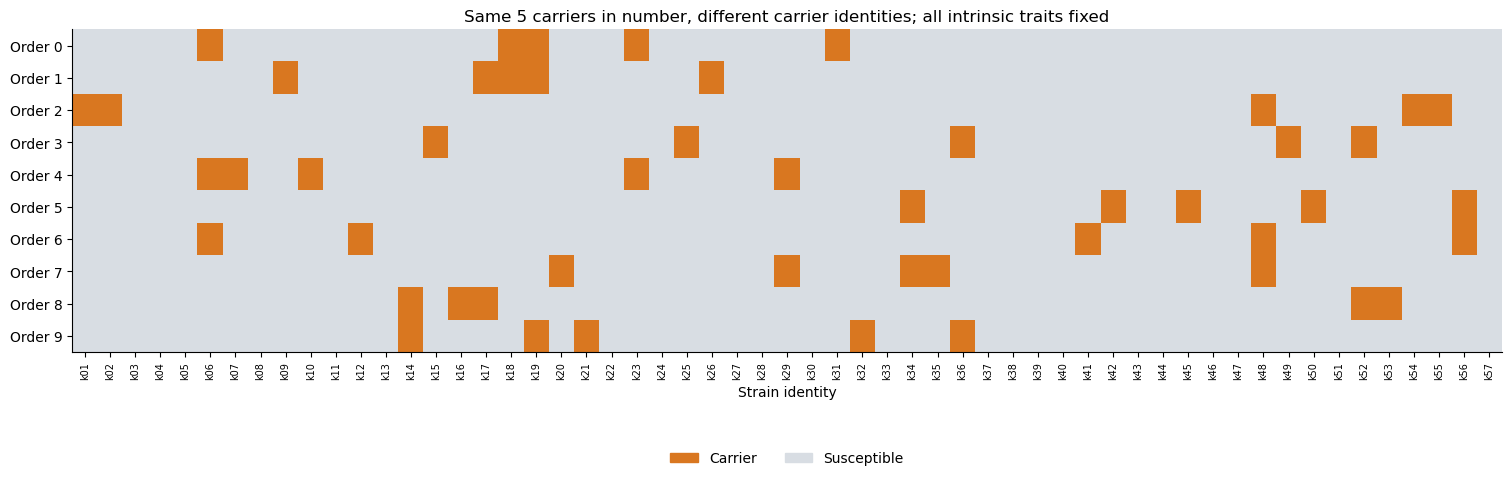

In [3]:
rng = np.random.default_rng(ASSIGNMENT_SEED)
orders = [rng.permutation(57) for _ in range(N_ORDERS)]
design_rows = []; MASKS = {}
for order_id,order in enumerate(orders):
    previous = np.zeros(57,bool)
    for k in sorted(c for c in COUNTS if 0<c<57):
        mask=np.zeros(57,bool);mask[order[:k]]=True
        assert mask.sum()==k and np.all(~previous|mask)
        previous=mask.copy()
        scenario=f'order{order_id:02d}_k{k:02d}'
        MASKS[scenario]=mask
        design_rows.append(dict(scenario=scenario,order_id=order_id,n_resistant=k,
                                reference=False,mask_id=hashlib.sha256(mask.tobytes()).hexdigest()[:16]))
for k in [0,57]:
    scenario=f'reference_k{k:02d}';mask=np.full(57,k==57,dtype=bool)
    MASKS[scenario]=mask
    design_rows.append(dict(scenario=scenario,order_id=-1,n_resistant=k,reference=True,
                            mask_id=hashlib.sha256(mask.tobytes()).hexdigest()[:16]))
design=pd.DataFrame(design_rows)
design.to_csv(OUT/'experiment_design.csv',index=False)
assignment_table=pd.concat([pd.DataFrame(dict(scenario=r.scenario,order_id=r.order_id,
                             n_resistant=r.n_resistant,strain=NAMES,carrier=MASKS[r.scenario]))
                             for r in design.itertuples()],ignore_index=True)
assignment_table.to_csv(OUT/'carrier_assignments.csv',index=False)
print(f'{len(design)} design cells; {design.mask_id.nunique()} distinct masks; up to {2*len(design)} treatment/control simulations.')
display(design.groupby(['reference','n_resistant']).agg(design_cells=('scenario','size'),distinct_masks=('mask_id','nunique')))

# Illustrate identity variation at the same count, not just increasing count.
example_k = 5 if 5 in COUNTS else sorted(k for k in COUNTS if 0<k<57)[0]
example=design[design.n_resistant.eq(example_k)&~design.reference]
fig,ax=plt.subplots(figsize=(15,4.7),layout='constrained')
ax.imshow(np.vstack([MASKS[s] for s in example.scenario]),aspect='auto',interpolation='nearest',
          cmap=ListedColormap(['#d8dde3','#d97720']),vmin=0,vmax=1)
ax.set_xticks(range(57),NAMES,rotation=90,fontsize=7)
ax.set_yticks(range(len(example)),[f'Order {i}' for i in example.order_id])
ax.set(title=f'Same {example_k} carriers in number, different carrier identities; all intrinsic traits fixed',xlabel='Strain identity')
ax.legend(handles=[Patch(color='#d97720',label='Carrier'),Patch(color='#d8dde3',label='Susceptible')],
          loc='upper center',bbox_to_anchor=(.5,-.27),ncol=2,frameon=False)
fig.savefig(FIGURES/'01_carrier_identity_repeats.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)


## 4. Simulate and audit every condition

Both arms have the same carrier mask and starting abundances. The only difference between arms is antibiotic addition at 4 h. At 24 h the community is diluted 100-fold into fresh drug-free medium, with extinction handling unchanged.

Cache keys include the original source hash, complete simulation parameters, exact carrier mask and initialization version. A completed compressed cache file is written atomically, so an interrupted write is not mistaken for a complete simulation.

This calls the original `simulate()` directly, allowing the zero-carrier baseline that the original convenience `run()` does not accept. The random carrier-mask initializer is active only during each simulation call.

In [4]:
SIM_KEYS = ['t','N','R','a','carrier','mu','ic50','pre_transfer','post_transfer','budget_error','t_transfer']
INITIALIZER_VERSION = 'fixed_traits_explicit_mask_v1'

def cached_simulation(mask,treated):
    p=replace(BASE,n_resistant=int(mask.sum()),dose=DOSE if treated else 0.)
    payload=dict(model=MODEL_SHA256,initializer=INITIALIZER_VERSION,
                 parameters=vars(p),carrier_mask=mask.tolist())
    key=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()
    path=CACHE/(key+'.npz')
    if path.exists() and not RECOMPUTE:
        with np.load(path,allow_pickle=False) as saved:
            sim={key:saved[key].copy() for key in SIM_KEYS}
        sim['params']=p
    else:
        with assigned_carriers(mask): sim=model.simulate(p)
        temporary=path.with_suffix('.tmp')
        with temporary.open('wb') as stream:
            np.savez_compressed(stream,**{key:sim[key] for key in SIM_KEYS})
        temporary.replace(path)
    # Audit actual outputs, including cached results.
    np.testing.assert_array_equal(sim['carrier'],mask)
    np.testing.assert_array_equal(sim['ic50'],IC50)
    np.testing.assert_allclose(sim['mu'],INTRINSIC*(1-p.resistance_cost*mask),rtol=1e-14)
    np.testing.assert_allclose(sim['N'][0],N0,rtol=1e-10)
    assert np.isfinite(sim['N']).all() and sim['N'].min()>=0
    assert abs(float(sim['budget_error']))<1e-6
    post=sim['pre_transfer']/p.dilution;post[post<p.floor]=0
    np.testing.assert_allclose(sim['post_transfer'],post,atol=1e-15)
    return sim

RUNS={};audit_rows=[]
for row in design.itertuples():
    mask=MASKS[row.scenario]
    for treated in [False,True]:
        sim=cached_simulation(mask,treated);RUNS[(row.scenario,treated)]=sim
        audit_rows.append(dict(scenario=row.scenario,treated=treated,n_resistant=row.n_resistant,
                               actual_initial_biomass=sim['N'][0].sum(),
                               actual_carrier_count=int(sim['carrier'].sum()),
                               mass_balance_error=float(sim['budget_error']),fixed_traits_verified=True))
    pre_t=model.snapshot(RUNS[(row.scenario,True)],4.)
    pre_c=model.snapshot(RUNS[(row.scenario,False)],4.)
    np.testing.assert_allclose(pre_t,pre_c,rtol=1e-12,atol=1e-15)
    print(f'{row.scenario}: complete')
assert model.community is original_community
AUDIT=pd.DataFrame(audit_rows);AUDIT.to_csv(OUT/'simulation_audit.csv',index=False)
print('All initial-state, fixed-trait, pre-treatment matching, dilution and mass-balance checks passed.')
display(AUDIT.groupby('n_resistant').agg(simulation_rows=('scenario','size'),
    initial_biomass=('actual_initial_biomass','first'),max_mass_error=('mass_balance_error',lambda x:np.abs(x).max())))


order00_k01: complete
order00_k05: complete
order00_k10: complete
order00_k20: complete
order00_k30: complete
order00_k40: complete
order01_k01: complete
order01_k05: complete
order01_k10: complete
order01_k20: complete
order01_k30: complete
order01_k40: complete
order02_k01: complete
order02_k05: complete
order02_k10: complete
order02_k20: complete
order02_k30: complete
order02_k40: complete
order03_k01: complete
order03_k05: complete
order03_k10: complete
order03_k20: complete
order03_k30: complete
order03_k40: complete
order04_k01: complete
order04_k05: complete
order04_k10: complete
order04_k20: complete
order04_k30: complete
order04_k40: complete
order05_k01: complete
order05_k05: complete
order05_k10: complete
order05_k20: complete
order05_k30: complete
order05_k40: complete
order06_k01: complete
order06_k05: complete
order06_k10: complete
order06_k20: complete
order06_k30: complete
order06_k40: complete
order07_k01: complete
order07_k05: complete
order07_k10: complete
order07_k2

,simulation_rows,initial_biomass,max_mass_error
n_resistant,,,
0,2,0.005,4.140203e-08
1,20,0.005,5.199760e-08
5,20,0.005,6.744274e-08
10,20,0.005,7.761496e-08
20,20,0.005,8.009111e-08
30,20,0.005,5.592315e-08
40,20,0.005,4.587676e-08
57,2,0.005,4.448601e-08


## 5. Compute baseline-relative outcomes at each sampling time

Baseline is **4 h**, not inoculation at 0 h, so pregrowth is not counted as an antibiotic effect. The 24 h sample is explicitly **before dilution**. The 48 h sample includes recovery after transfer.

The baseline proxy is total resistant biomass B_R(4). The model's maximum removal capacity is `vmax × B_R(4)`; at the actual dose the instantaneous enzymatic removal rate is `vmax × B_R(4) × dose/(Km + dose)`. These are proportional proxies here, so their Spearman correlations are identical. Correlation is computed against baseline capacity, not the final abundance of selected survivors.

Biomass and detected strain counts are retained to distinguish extinction, non-detection, loss of evenness and resistant takeover. A nonzero community with only one strain can legitimately have Shannon 0; a zero-biomass community is assigned undefined diversity/composition. A zero baseline Shannon makes retention undefined.

In [5]:
def metrics(x,mask):
    b=float(np.sum(x))
    if b<=0:
        return dict(biomass=0.,shannon=np.nan,resistant_share=np.nan,
                    detected=0,susceptible_detected=0,extinct=True)
    p=x/b;detected=(p>=BASE.detection_rel)&(x>0)
    return dict(biomass=b,shannon=float(-(p[p>0]*np.log(p[p>0])).sum()),
                resistant_share=float(x[mask].sum()/b),detected=int(detected.sum()),
                susceptible_detected=int((detected&~mask).sum()),extinct=False)

def ratio(a,b):return float(a/b) if np.isfinite(a) and np.isfinite(b) and b>0 else np.nan

def bc(x,y):
    if x.sum()<=0 or y.sum()<=0:return np.nan
    return float(.5*np.abs(x/x.sum()-y/y.sum()).sum())

outcome_rows=[];snapshot_rows=[]
for d in design.itertuples():
    mask=MASKS[d.scenario];t=RUNS[(d.scenario,True)];c=RUNS[(d.scenario,False)]
    bt=model.snapshot(t,4.);bc0=model.snapshot(c,4.)
    mt0=metrics(bt,mask);mc0=metrics(bc0,mask)
    bR=float(bt[mask].sum())
    baseline=dict(baseline_carrier_biomass_OD=bR,
                  baseline_carrier_share=ratio(bR,bt.sum()),
                  baseline_max_degradation_ug_ml_h=BASE.vmax*bR,
                  baseline_actual_removal_ug_ml_h=BASE.vmax*bR*DOSE/(BASE.km+DOSE),
                  baseline_shannon=mt0['shannon'],baseline_total_biomass=mt0['biomass'])
    for hour in SAMPLE_HOURS:
        xt=model.snapshot(t,hour);xc=model.snapshot(c,hour)
        mt=metrics(xt,mask);mc=metrics(xc,mask)
        ht=ratio(mt['shannon'],mt0['shannon']);hc=ratio(mc['shannon'],mc0['shannon'])
        bct=bc(xt,bt);bcc=bc(xc,bc0)
        outcome_rows.append(dict(scenario=d.scenario,order_id=d.order_id,n_resistant=d.n_resistant,
            reference=d.reference,mask_id=d.mask_id,hour=hour,**baseline,
            shannon_retention=ht,control_shannon_retention=hc,
            adjusted_shannon_retention=ratio(ht,hc),
            bray_curtis_to_baseline=bct,control_bray_curtis_to_baseline=bcc,
            excess_bray_curtis=bct-bcc,bray_curtis_to_control=bc(xt,xc),
            treated_biomass=mt['biomass'],control_biomass=mc['biomass'],
            biomass_ratio_to_control=ratio(mt['biomass'],mc['biomass']),
            treated_shannon=mt['shannon'],control_shannon=mc['shannon'],
            resistant_share=mt['resistant_share'],detected_strains=mt['detected'],
            susceptible_detected=mt['susceptible_detected'],
            susceptible_detected_fraction=ratio(mt['susceptible_detected'],57-d.n_resistant),
            treated_extinct=mt['extinct'],control_extinct=mc['extinct']))
    for treated,sim in [(True,t),(False,c)]:
        for hour in [0.,4.]+SAMPLE_HOURS:
            x=model.snapshot(sim,hour);total=x.sum()
            for i,name in enumerate(NAMES):
                snapshot_rows.append(dict(scenario=d.scenario,order_id=d.order_id,n_resistant=d.n_resistant,
                    treated=treated,hour=hour,strain=name,carrier=bool(mask[i]),
                    absolute_biomass_OD=x[i],relative_abundance=x[i]/total if total>0 else np.nan))
outcomes=pd.DataFrame(outcome_rows)
snapshots=pd.DataFrame(snapshot_rows)
outcomes.to_csv(OUT/'all_timepoint_outcomes.csv',index=False)
snapshots.to_csv(OUT/'strain_sampling_timepoints.csv.gz',index=False,compression='gzip')
display(outcomes[['scenario','hour','baseline_carrier_biomass_OD','shannon_retention',
                  'bray_curtis_to_baseline','adjusted_shannon_retention','excess_bray_curtis','treated_extinct']].round(4))
# Report excluded extinction outcomes explicitly; do not hide them by dropping NaNs.
extinction_summary=outcomes.groupby(['reference','n_resistant','hour']).agg(
    design_cells=('scenario','size'),extinct=('treated_extinct','sum'),
    undefined_shannon=('shannon_retention',lambda x:int(x.isna().sum())),
    undefined_bray_curtis=('bray_curtis_to_baseline',lambda x:int(x.isna().sum())))
display(extinction_summary);extinction_summary.to_csv(OUT/'extinction_and_missing_outcomes.csv')


,scenario,hour,baseline_carrier_biomass_OD,shannon_retention,bray_curtis_to_baseline,adjusted_shannon_retention,excess_bray_curtis,treated_extinct
0,order00_k01,6.0,0.0009,0.8831,0.2329,0.8850,0.2085,False
1,order00_k01,24.0,0.0009,0.5786,0.5603,0.5839,0.4868,False
2,order00_k01,48.0,0.0009,0.4538,0.6665,0.4697,0.4944,False
3,order00_k05,6.0,0.0035,0.9454,0.2276,0.9474,0.2037,False
4,order00_k05,24.0,0.0035,0.9226,0.2458,0.9312,0.1739,False
...,...,...,...,...,...,...,...,...
181,reference_k00,24.0,0.0000,NaN,NaN,NaN,NaN,True
182,reference_k00,48.0,0.0000,NaN,NaN,NaN,NaN,True
183,reference_k57,6.0,0.0364,0.9977,0.0241,1.0000,0.0000,False
184,reference_k57,24.0,0.0364,0.9888,0.0791,1.0000,0.0000,False


design_cells  extinct  undefined_shannon  \
reference n_resistant hour                                             
False     1           6.0             10        0                  0   
                      24.0            10        0                  0   
                      48.0            10        0                  0   
          5           6.0             10        0                  0   
                      24.0            10        0                  0   
                      48.0            10        0                  0   
          10          6.0             10        0                  0   
                      24.0            10        0                  0   
                      48.0            10        0                  0   
          20          6.0             10        0                  0   
                      24.0            10        0                  0   
                      48.0            10        0                  0   
          30          6.0             10        0                  0   
                      24.0            10        0                  0   
                      48.0            10        0                  0   
          40          6.0             10        0                  0   
                      24.0            10        0                  0   
                      48.0            10        0                  0   
True      0           6.0              1        0                  0   
                      24.0             1        1                  1   
                      48.0             1        1                  1   
          57          6.0              1        0                  0   
                      24.0             1        0                  0   
                      48.0             1        0                  0   

                            undefined_bray_curtis  
reference n_resistant hour                         
False     1           6.0                       0  
                      24.0                      0  
                      48.0                      0  
          5           6.0                       0  
                      24.0                      0  
                      48.0                      0  
          10          6.0                       0  
                      24.0                      0  
                      48.0                      0  
          20          6.0                       0  
                      24.0                      0  
                      48.0                      0  
          30          6.0                       0  
                      24.0                      0  
                      48.0                      0  
          40          6.0                       0  
                      24.0                      0  
                      48.0                      0  
True      0           6.0                       0  
                      24.0                      1  
                      48.0                      1  
          57          6.0                       0  
                      24.0                      0  
                      48.0                      0

## 6. Primary scatterplots: the proposed analysis

Each point is one carrier assignment/count design at one sampling time. Its x-value is measured **before** treatment. Colors indicate carrier count; the gray square and star are shared zero-carrier and all-carrier reference conditions.

We show zero on a **symlog axis**: linear close to zero and logarithmic for positive carrier biomass above the stated transition. This avoids adding an arbitrary pseudocount. Zero-carrier outcomes that become extinct have no defined Shannon/Bray–Curtis point; the extinction table above still reports them.

The dashed line is an optional **descriptive least-squares guide using log10(x)** across intermediate-count designs. It is not the assumed mechanism and can overshoot bounded outcomes. Spearman ρ is the primary association measure because it tests monotonic association without requiring a straight line. No fitted line is drawn if outcomes are constant. The two shared endpoint references are excluded from fits and correlations.


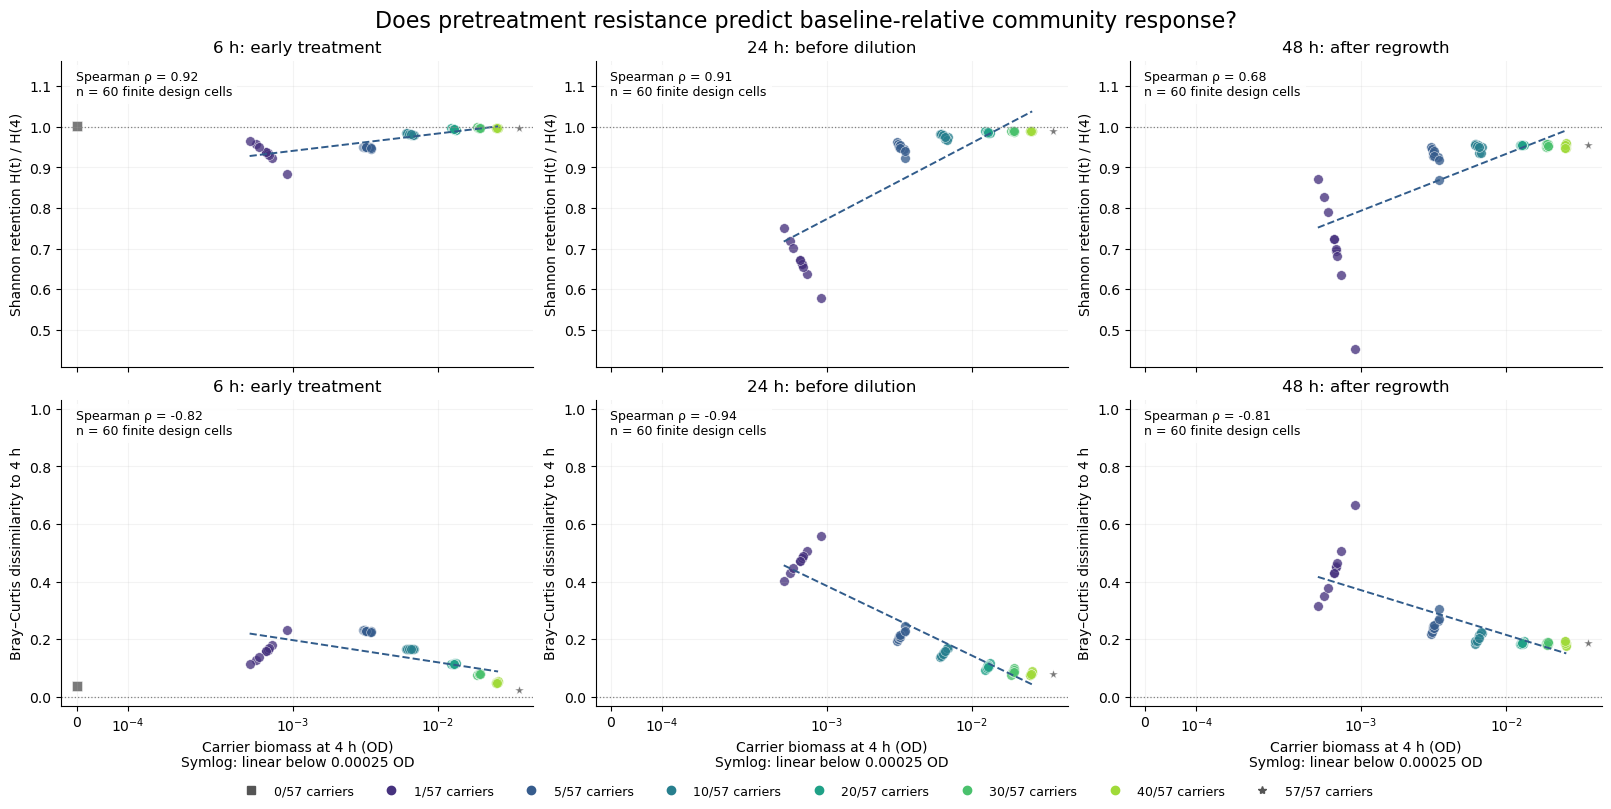

In [6]:
X = 'baseline_carrier_biomass_OD'
X_LABEL = 'Baseline resistant-carrier biomass at 4 h (OD; proxy for β-lactamase capacity)'
INTERIOR = outcomes[~outcomes.reference].copy()
COUNT_COLORS={k:plt.get_cmap('viridis')(i/max(len(COUNTS)-1,1)) for i,k in enumerate(sorted(COUNTS))}
positive=outcomes.loc[outcomes[X]>0,X]
LINTHRESH=float(positive.min()/2)

def finite_pairs(g,metric):
    return g[np.isfinite(g[X])&np.isfinite(g[metric])&(g[X]>0)]

def safe_rho(x,y):
    x=np.asarray(x,float);y=np.asarray(y,float)
    valid=np.isfinite(x)&np.isfinite(y);x=x[valid];y=y[valid]
    if len(x)<3 or np.ptp(x)<1e-15 or np.ptp(y)<1e-12:return np.nan
    return float(spearmanr(x,y).statistic)

def scatter_panels(specification,filename,title):
    fig,axes=plt.subplots(len(specification),len(SAMPLE_HOURS),figsize=(16,8),
                           sharex=True,squeeze=False,layout='constrained')
    for row,(metric,ylabel,reference) in enumerate(specification):
        finite_values=outcomes.loc[np.isfinite(outcomes[metric]),metric]
        lower=min(float(finite_values.min()),reference)
        upper=max(float(finite_values.max()),reference)
        padding=max((upper-lower)*.08,.015)
        for col,hour in enumerate(SAMPLE_HOURS):
            ax=axes[row,col];g=outcomes[outcomes.hour.eq(hour)]
            for k in sorted(COUNTS):
                z=g[g.n_resistant.eq(k)]
                ax.scatter(z[X],z[metric],s=48,color=COUNT_COLORS[k] if k not in [0,57] else '#555555',
                           marker='s' if k==0 else ('*' if k==57 else 'o'),
                           alpha=.78,edgecolor='white',linewidth=.4)
            v=finite_pairs(g[~g.reference],metric)
            rho=safe_rho(v[X],v[metric])
            if len(v)>2 and np.ptp(v[metric])>1e-12:
                slope,intercept=np.polyfit(np.log10(v[X]),v[metric],1)
                xx=np.geomspace(v[X].min(),v[X].max(),100)
                ax.plot(xx,intercept+slope*np.log10(xx),'--',color='#315c8b',lw=1.4)
            ax.set_xscale('symlog',linthresh=LINTHRESH,linscale=.8)
            ax.set_xlim(-LINTHRESH*.12,outcomes[X].max()*1.25)
            ax.axhline(reference,color='gray',ls=':',lw=.9)
            ax.set_title(f'{hour:g} h: '+{6.:'early treatment',24.:'before dilution',48.:'after regrowth'}[hour])
            ax.set_ylabel(ylabel)
            ax.text(.03,.97,f'Spearman ρ = {rho:.2f}\nn = {len(v)} finite design cells',
                    transform=ax.transAxes,ha='left',va='top',fontsize=9,
                    bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set_ylim(lower-padding,upper+(max(padding,.16) if 'shannon' in metric else padding))
            if metric=='bray_curtis_to_baseline':ax.set_ylim(-.03,1.03)
            ax.grid(alpha=.15)
    handles=[plt.Line2D([0],[0],marker='s' if k==0 else ('*' if k==57 else 'o'),ls='',
              color='#555555' if k in [0,57] else COUNT_COLORS[k],label=f'{k}/57 carriers') for k in sorted(COUNTS)]
    fig.legend(handles=handles,loc='outside lower center',ncol=8,frameon=False,fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel('Carrier biomass at 4 h (OD)\nSymlog: linear below '+f'{LINTHRESH:.2g} OD',fontsize=10)
    fig.suptitle(title,fontsize=16)
    fig.savefig(FIGURES/filename,dpi=180,bbox_inches='tight');plt.show();plt.close(fig)

scatter_panels([('shannon_retention','Shannon retention H(t) / H(4)',1),
                ('bray_curtis_to_baseline','Bray–Curtis dissimilarity to 4 h',0)],
               '02_primary_correlations.png','Does pretreatment resistance predict baseline-relative community response?')


## 7. Repeat the analysis after accounting for untreated changes

Competition, resource depletion, resistance costs and dilution can alter a community without antibiotics. These panels compare each treated design with its own untreated trajectory.

**Top:** retention relative to the untreated retention. **Bottom:** treated displacement minus untreated displacement. A positive excess Bray–Curtis means greater displacement magnitude under treatment, but it does not say that the two communities changed in the same direction. Use the direct treated–control Bray–Curtis column to inspect their final difference.

These controls strengthen interpretation within the model. They do not convert a simulated correlation into independent empirical evidence of causation in natural microbiomes.

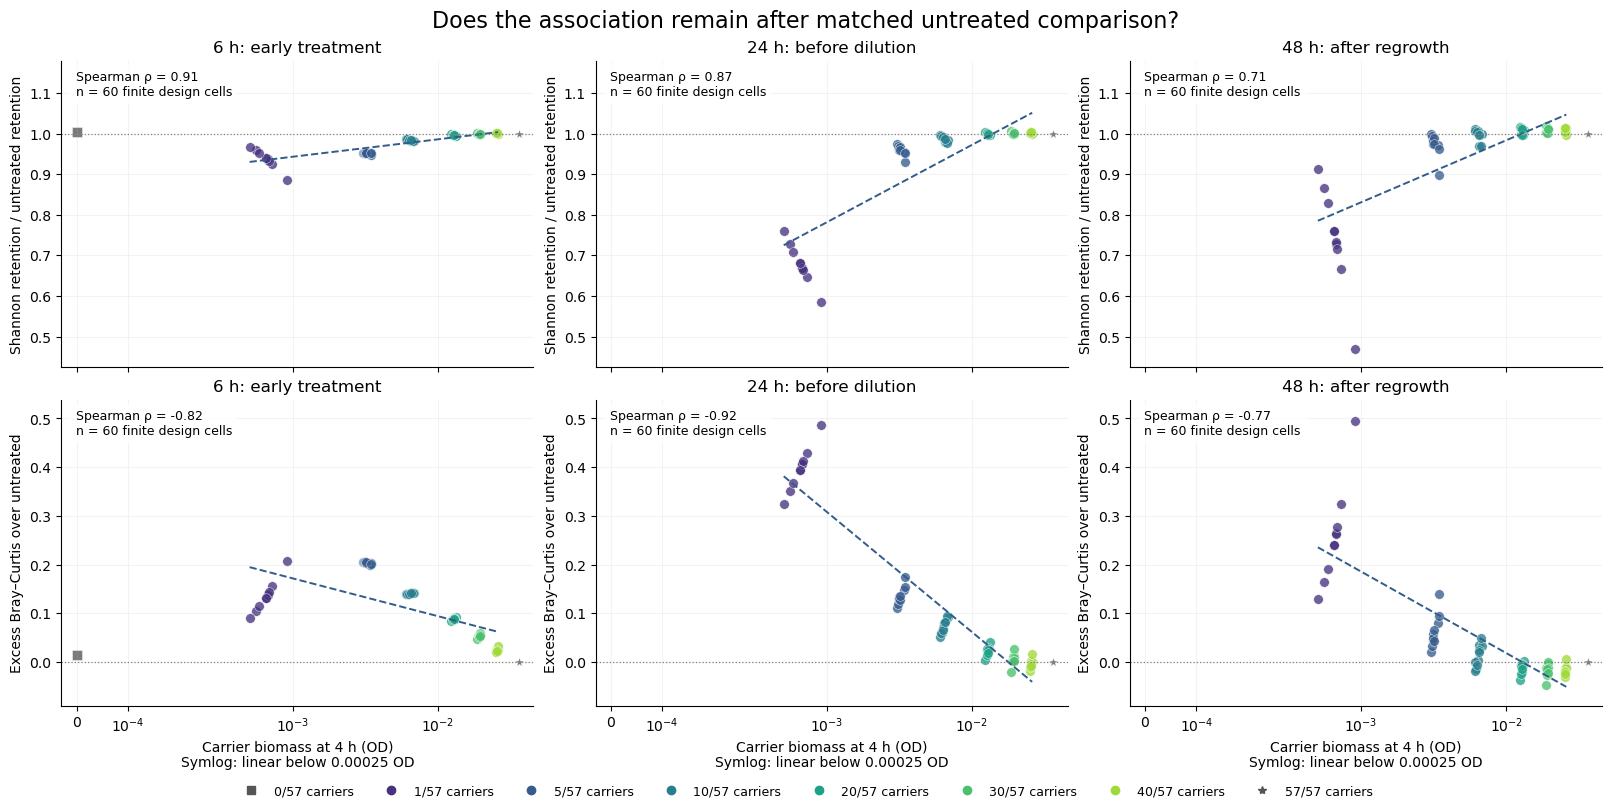

In [7]:
scatter_panels([('adjusted_shannon_retention','Shannon retention / untreated retention',1),
                ('excess_bray_curtis','Excess Bray–Curtis over untreated',0)],
               '03_untreated_adjusted_correlations.png','Does the association remain after matched untreated comparison?')


## 8. Correlation estimates and uncertainty over carrier identities

We report **Spearman ρ** and, secondarily, **Pearson r with log10(x)** for each metric at each time. No ordinary independent-point p-values are reported: counts within an assignment order are deliberately nested, and repeated sampling times are paired observations of the same trajectories.

For uncertainty, sample entire carrier-order blocks with replacement. Every selected block carries all its counts together; the same block draws are used across time points and metrics. The 2.5th and 97.5th percentiles give an exploratory 95% **assignment-order bootstrap interval for pooled Spearman ρ**. This reflects variation over random resistance assignments conditional on this fixed community and chosen count grid. It does not represent uncertainty across different microbiomes, model parameters, experimental measurement errors or alternative biological mechanisms. Ten orders is a modest number; expand `N_ORDERS` for a more stable assignment analysis.

Correlations exclude zero/all-carrier shared references. Undefined outcomes are excluded metric by metric and sample sizes are reported. If whole communities go extinct, missingness is biologically informative: a correlation among survivors is not a complete description of resilience. If all values are constant, correlation is undefined rather than evidence of no effect.


,metric,hour,n_finite_design_cells,n_distinct_masks,n_assignment_orders,spearman_rho,assignment_bootstrap_low,assignment_bootstrap_high,pearson_r_log10_x,valid_bootstraps
0,shannon_retention,6.0,60,59,10,0.916,0.903,0.939,0.888,1000
1,shannon_retention,24.0,60,59,10,0.909,0.864,0.952,0.868,1000
2,shannon_retention,48.0,60,59,10,0.682,0.561,0.805,0.757,1000
3,bray_curtis_to_baseline,6.0,60,59,10,-0.819,-0.862,-0.789,-0.686,1000
4,bray_curtis_to_baseline,24.0,60,59,10,-0.937,-0.954,-0.926,-0.950,1000
5,bray_curtis_to_baseline,48.0,60,59,10,-0.808,-0.905,-0.699,-0.835,1000
6,adjusted_shannon_retention,6.0,60,59,10,0.906,0.887,0.934,0.888,1000
7,adjusted_shannon_retention,24.0,60,59,10,0.874,0.831,0.932,0.869,1000
8,adjusted_shannon_retention,48.0,60,59,10,0.712,0.621,0.833,0.769,1000
9,excess_bray_curtis,6.0,60,59,10,-0.821,-0.860,-0.795,-0.688,1000


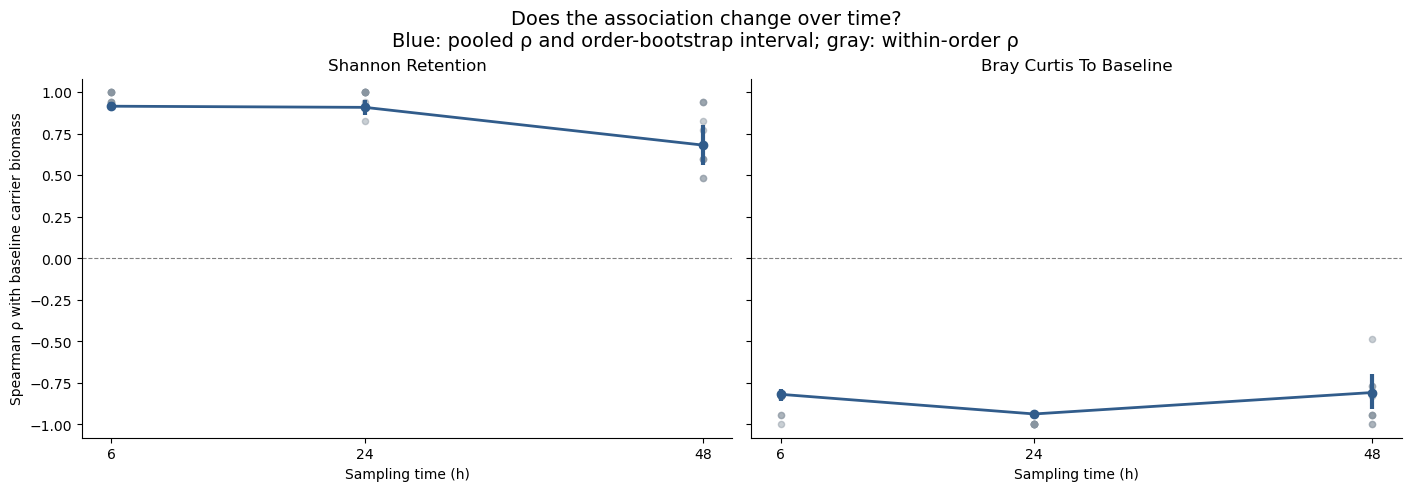

In [8]:
METRICS = ['shannon_retention','bray_curtis_to_baseline',
           'adjusted_shannon_retention','excess_bray_curtis']
boot_rng=np.random.default_rng(BOOTSTRAP_SEED)
block_draws=boot_rng.integers(0,N_ORDERS,size=(BOOTSTRAPS,N_ORDERS))
correlation_rows=[];order_rows=[]
for metric in METRICS:
    for hour in SAMPLE_HOURS:
        g=finite_pairs(INTERIOR[INTERIOR.hour.eq(hour)],metric)
        rho=safe_rho(g[X],g[metric])
        if len(g)>=3 and np.ptp(g[metric])>1e-12:
            pearson_log=float(pearsonr(np.log10(g[X]),g[metric]).statistic)
        else:pearson_log=np.nan
        blocks=[]
        for order_id in range(N_ORDERS):
            z=g[g.order_id.eq(order_id)]
            blocks.append(z[[X,metric]].to_numpy(float))
            order_rows.append(dict(metric=metric,hour=hour,order_id=order_id,
                                   n=len(z),spearman_rho=safe_rho(z[X],z[metric])))
        bootstrap_rhos=[]
        for indices in block_draws:
            values=np.concatenate([blocks[i] for i in indices],axis=0)
            bootstrap_rhos.append(safe_rho(values[:,0],values[:,1]))
        finite_boot=np.array(bootstrap_rhos)[np.isfinite(bootstrap_rhos)]
        low,high=np.quantile(finite_boot,[.025,.975]) if len(finite_boot) else (np.nan,np.nan)
        correlation_rows.append(dict(metric=metric,hour=hour,n_finite_design_cells=len(g),
            n_distinct_masks=g.mask_id.nunique(),n_assignment_orders=g.order_id.nunique(),
            spearman_rho=rho,assignment_bootstrap_low=low,assignment_bootstrap_high=high,
            pearson_r_log10_x=pearson_log,valid_bootstraps=len(finite_boot)))
correlations=pd.DataFrame(correlation_rows);by_order=pd.DataFrame(order_rows)
correlations.to_csv(OUT/'timepoint_correlations.csv',index=False)
by_order.to_csv(OUT/'correlations_within_each_assignment_order.csv',index=False)
display(correlations.round(3))

fig,axes=plt.subplots(1,2,figsize=(14,4.8),layout='constrained',sharey=True)
for ax,metric in zip(axes,['shannon_retention','bray_curtis_to_baseline']):
    z=correlations[correlations.metric.eq(metric)].sort_values('hour')
    for hour in SAMPLE_HOURS:
        values=by_order[(by_order.metric==metric)&(by_order.hour==hour)].spearman_rho
        ax.scatter(np.full(len(values),hour),values,s=20,color='#8995a0',alpha=.45)
    ax.plot(z.hour,z.spearman_rho,'-o',color='#315c8b',lw=2)
    ax.vlines(z.hour,z.assignment_bootstrap_low,z.assignment_bootstrap_high,color='#315c8b',lw=3)
    ax.axhline(0,color='gray',ls='--',lw=.8)
    ax.set(title=metric.replace('_',' ').title(),xlabel='Sampling time (h)',xticks=SAMPLE_HOURS,ylim=(-1.08,1.08))
axes[0].set_ylabel('Spearman ρ with baseline carrier biomass')
fig.suptitle('Does the association change over time?\nBlue: pooled ρ and order-bootstrap interval; gray: within-order ρ',fontsize=14)
fig.savefig(FIGURES/'04_association_over_time.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)


## 9. Show the underlying biomass and composition trajectories

These are representative trajectories for **assignment order 0**, plus the two shared reference conditions. They are not a random subset chosen for a desired outcome. Every colored band is one of the same 57 strains, with a fixed color throughout. Total stack height is absolute biomass in OD; each strain's fraction of that height is its relative abundance.

Panels share a scale. Left = untreated; right = treated. The vertical drop at 24 h is the imposed dilution, not antibiotic killing. Zero-carrier extinction can be nearly invisible on this biomass scale; the extinction table preserves that outcome. Detailed sampled strain abundances and all full trajectories in compressed simulation caches are saved for inspection.

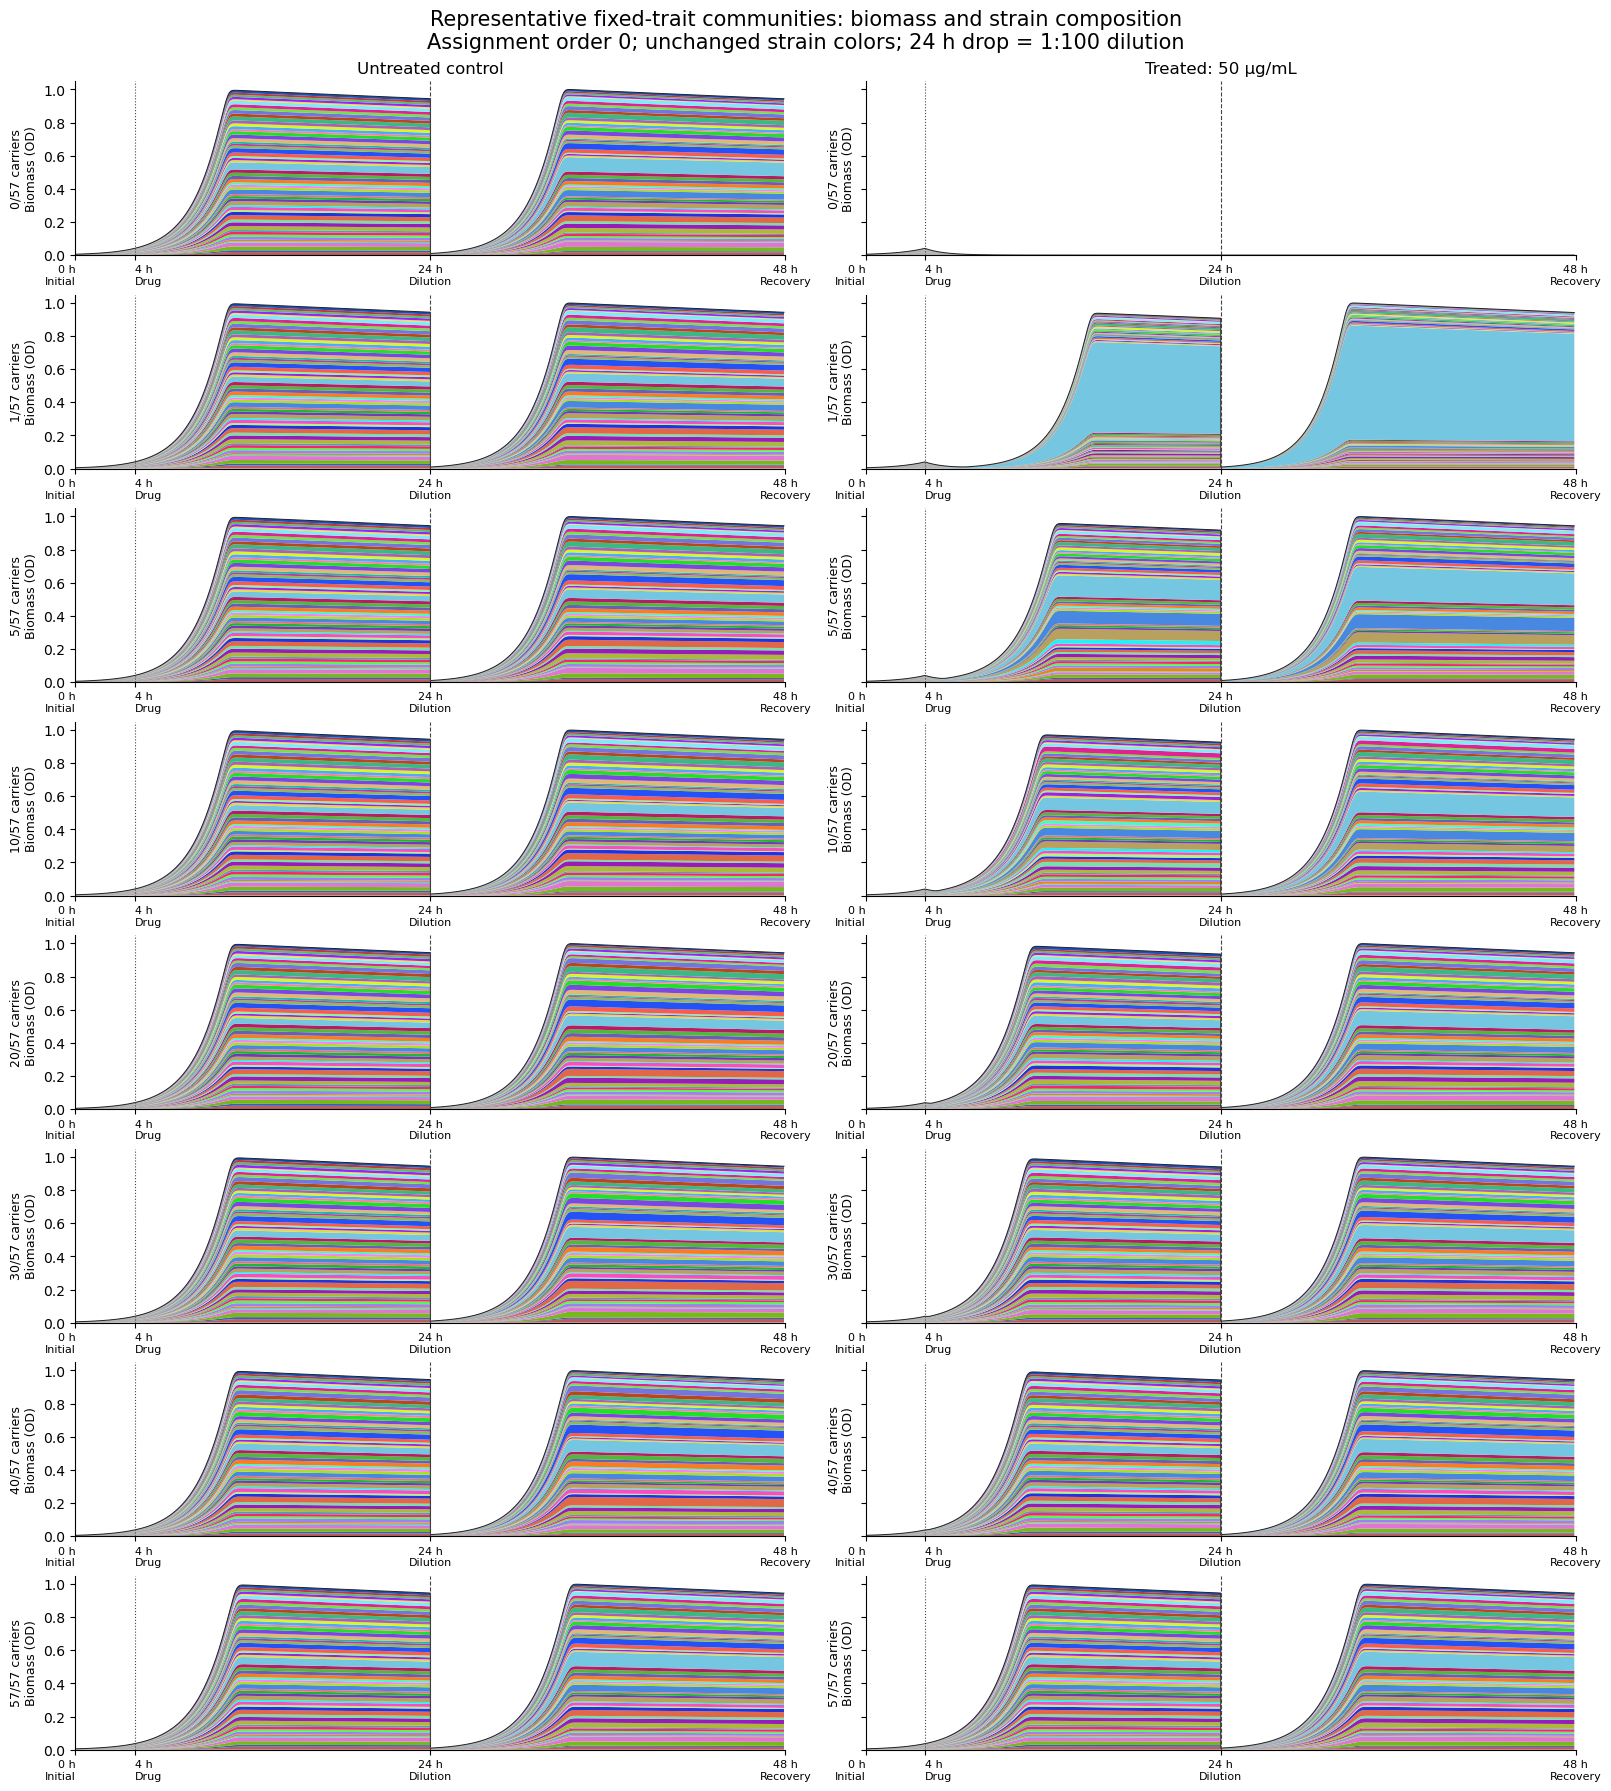

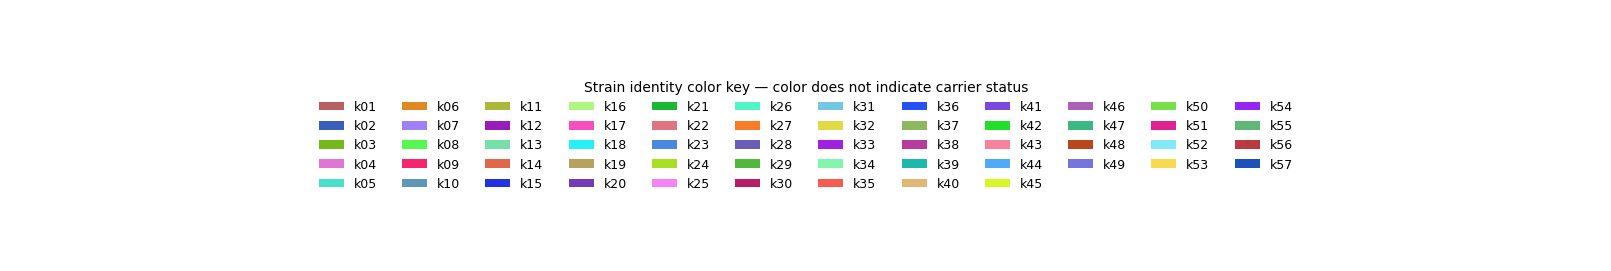

In [9]:
STRAIN_COLORS=[colorsys.hsv_to_rgb((i*.61803398875)%1,[.48,.68,.85][i%3],[.72,.88,.97][(i//3)%3]) for i in range(57)]
representatives=design[(design.order_id.eq(0))|design.reference].sort_values('n_resistant')
fig,axes=plt.subplots(len(representatives),2,figsize=(16,2.1*len(representatives)+1),
                       sharex=True,sharey=True,squeeze=False,layout='constrained')
max_b=max(RUNS[(s,t)]['N'].sum(axis=1).max() for s in representatives.scenario for t in [False,True])
for row,d in enumerate(representatives.itertuples()):
    for col,treated in enumerate([False,True]):
        sim=RUNS[(d.scenario,treated)];ax=axes[row,col];time=np.maximum.accumulate(sim['t'])
        ax.stackplot(time,sim['N'].T,colors=STRAIN_COLORS,linewidth=0)
        ax.plot(time,sim['N'].sum(axis=1),color='#222222',lw=.7)
        ax.axvline(4,color='#444444',ls=':',lw=.8);ax.axvline(24,color='#444444',ls='--',lw=.8)
        ax.set_ylabel(f'{d.n_resistant}/57 carriers\nBiomass (OD)',fontsize=9)
        ax.set_xlim(0,48);ax.set_ylim(0,max_b*1.05)
        ax.set_xticks([0,4,24,48],['0 h\nInitial','4 h\nDrug','24 h\nDilution','48 h\nRecovery'],fontsize=8)
        ax.tick_params(labelbottom=True)
        ax.get_xticklabels()[0].set_ha('right');ax.get_xticklabels()[1].set_ha('left')
        if row==0:ax.set_title('Untreated control' if not treated else f'Treated: {DOSE:g} µg/mL')
fig.suptitle('Representative fixed-trait communities: biomass and strain composition\nAssignment order 0; unchanged strain colors; 24 h drop = 1:100 dilution',fontsize=15)
fig.savefig(FIGURES/'05_representative_absolute_composition.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(16,2.6),layout='constrained');ax.axis('off')
ax.legend(handles=[Patch(facecolor=c,label=s) for s,c in zip(NAMES,STRAIN_COLORS)],loc='center',
          ncol=12,frameon=False,fontsize=9,title='Strain identity color key — color does not indicate carrier status')
fig.savefig(FIGURES/'strain_color_key.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)


## 10. Check resistant takeover, biomass recovery and time-dependent diversity

A high community biomass ratio can coexist with low diversity retention if a carrier dominates. These panels summarize all intermediate-count designs, keeping repeated times distinct. The median and min–max range describe variation over the sampled carrier orders; ranges are **not confidence intervals**. The all-sensitive and all-resistant references remain separately available in the outcome table.

Counts at a relative detection threshold describe non-detection, not necessarily extinction. For susceptible retention, the denominator is 57 − carrier count, so carrier-count comparisons do not mistake fewer initially susceptible strains for poorer survival.

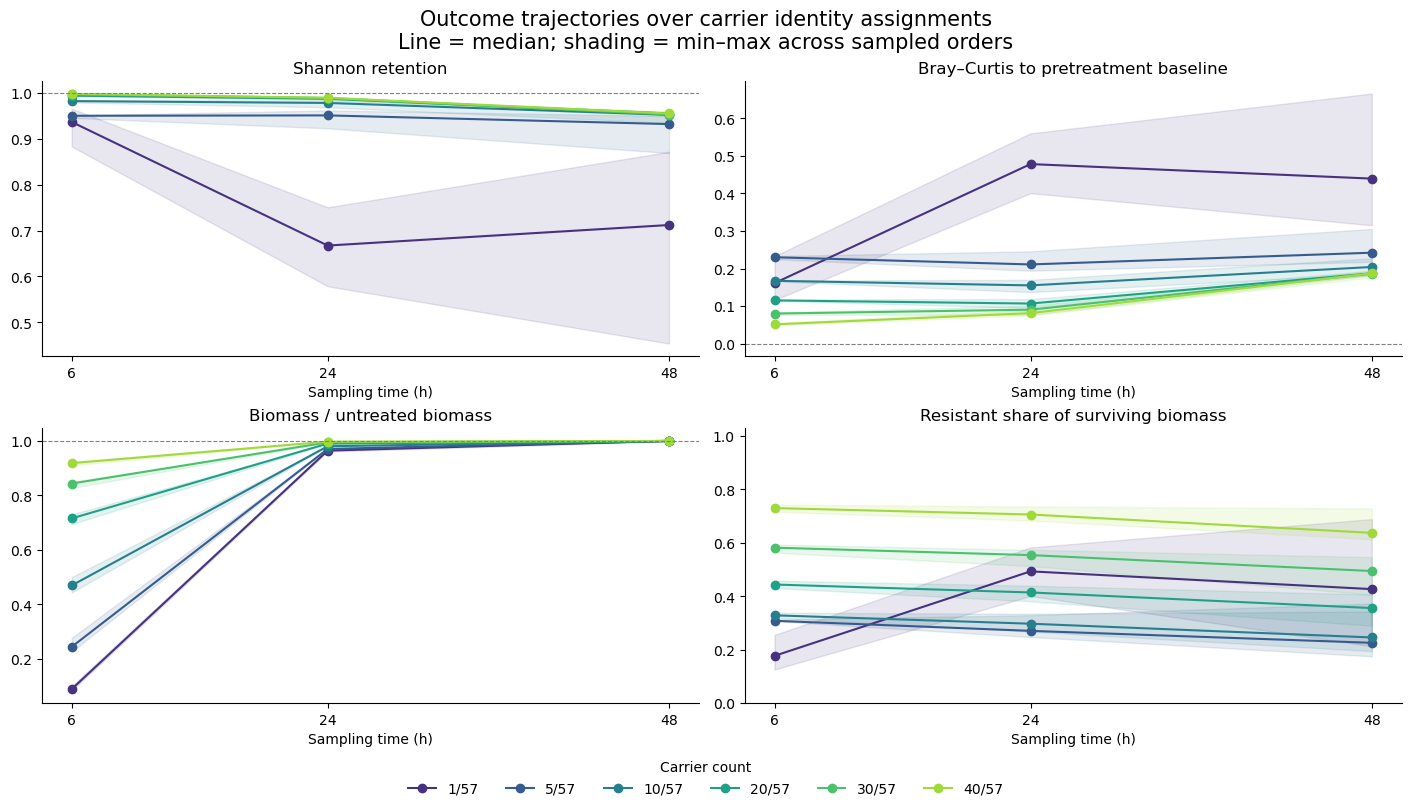

cells  extinct  median_baseline_carrier_OD  \
n_resistant hour                                               
0           6.0       1        0                      0.0000   
            24.0      1        1                      0.0000   
            48.0      1        1                      0.0000   
1           6.0      10        0                      0.0007   
            24.0     10        0                      0.0007   
            48.0     10        0                      0.0007   
5           6.0      10        0                      0.0032   
            24.0     10        0                      0.0032   
            48.0     10        0                      0.0032   
10          6.0      10        0                      0.0064   
            24.0     10        0                      0.0064   
            48.0     10        0                      0.0064   
20          6.0      10        0                      0.0128   
            24.0     10        0                      0.0128   
            48.0     10        0                      0.0128   
30          6.0      10        0                      0.0192   
            24.0     10        0                      0.0192   
            48.0     10        0                      0.0192   
40          6.0      10        0                      0.0256   
            24.0     10        0                      0.0256   
            48.0     10        0                      0.0256   
57          6.0       1        0                      0.0364   
            24.0      1        0                      0.0364   
            48.0      1        0                      0.0364   

                  median_shannon_retention  median_BC  median_biomass_ratio  \
n_resistant hour                                                              
0           6.0                     1.0018     0.0390                0.0734   
            24.0                       NaN        NaN                0.0000   
            48.0                       NaN        NaN                0.0000   
1           6.0                     0.9365     0.1611                0.0888   
            24.0                    0.6673     0.4783                0.9646   
            48.0                    0.7120     0.4397                1.0007   
5           6.0                     0.9500     0.2300                0.2440   
            24.0                    0.9508     0.2109                0.9708   
            48.0                    0.9319     0.2422                1.0002   
10          6.0                     0.9819     0.1673                0.4694   
            24.0                    0.9779     0.1551                0.9807   
            48.0                    0.9520     0.2041                1.0002   
20          6.0                     0.9938     0.1150                0.7157   
            24.0                    0.9869     0.1066                0.9904   
            48.0                    0.9549     0.1870                1.0002   
30          6.0                     0.9966     0.0800                0.8438   
            24.0                    0.9887     0.0903                0.9950   
            48.0                    0.9526     0.1863                1.0001   
40          6.0                     0.9977     0.0511                0.9186   
            24.0                    0.9892     0.0811                0.9976   
            48.0                    0.9550     0.1871                1.0001   
57          6.0                     0.9977     0.0241                1.0000   
            24.0                    0.9888     0.0791                1.0000   
            48.0                    0.9548     0.1870                1.0000   

                  median_susceptible_detected_fraction  
n_resistant hour                                        
0           6.0                                    1.0  
            24.0                                   0.0  
            48.0                                   0.0  
1           6

In [10]:
fig,axes=plt.subplots(2,2,figsize=(14,8),layout='constrained')
summary_specs=[('shannon_retention','Shannon retention',1),
               ('bray_curtis_to_baseline','Bray–Curtis to pretreatment baseline',0),
               ('biomass_ratio_to_control','Biomass / untreated biomass',1),
               ('resistant_share','Resistant share of surviving biomass',None)]
for ax,(metric,title,ref) in zip(axes.flat,summary_specs):
    for k in sorted(c for c in COUNTS if 0<c<57):
        z=INTERIOR[INTERIOR.n_resistant.eq(k)].groupby('hour')[metric].agg(['median','min','max']).reindex(SAMPLE_HOURS)
        ax.plot(z.index,z['median'],'-o',color=COUNT_COLORS[k],label=f'{k}/57')
        ax.fill_between(z.index,z['min'],z['max'],color=COUNT_COLORS[k],alpha=.12)
    if ref is not None:ax.axhline(ref,color='gray',ls='--',lw=.8)
    ax.set(title=title,xlabel='Sampling time (h)',xticks=SAMPLE_HOURS)
axes[1,1].set_ylim(0,1.03)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=6,title='Carrier count',frameon=False)
fig.suptitle('Outcome trajectories over carrier identity assignments\nLine = median; shading = min–max across sampled orders',fontsize=15)
fig.savefig(FIGURES/'06_outcome_trajectories.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)

# Compact end-of-treatment and recovery summary, including references.
report=outcomes.groupby(['n_resistant','hour']).agg(
    cells=('scenario','size'),extinct=('treated_extinct','sum'),
    median_baseline_carrier_OD=(X,'median'),median_shannon_retention=('shannon_retention','median'),
    median_BC=('bray_curtis_to_baseline','median'),median_biomass_ratio=('biomass_ratio_to_control','median'),
    median_susceptible_detected_fraction=('susceptible_detected_fraction','median'))
display(report.round(4));report.to_csv(OUT/'outcome_summary_by_count_time.csv')


## 11. Read the findings without overinterpreting them

The next cell prints **computed** association estimates at each time and reports undefined/extinct outcomes. It does not decide whether the hypothesis was supported before seeing the results.

When writing the story, ask:

1. Does the direction match higher Shannon retention and lower Bray–Curtis with greater baseline capacity? Does the relationship look monotonic, saturating or threshold-like?
2. Does it persist with untreated adjustment and across carrier orders? Are some identities unusually protective at the same count?
3. Does the effect occur during treatment, recovery, or both? Remember that the 24–48 h interval includes dilution and fresh nutrients.
4. Is restored biomass accompanied by diversity/composition recovery, or by resistant takeover? Are undefined outcomes caused by extinction?
5. Could resistant count, carrier growth costs, pregrowth biomass and identity explain part of the pattern? Would a fixed-carrier-biomass design give the same result?

A favorable correlation is **consistent with the protection mechanism encoded in this model**. It is not independent evidence that the mechanism operates in patient communities: carrier immunity and enzymatic degradation were built into the equations. A follow-up degradation-off experiment can isolate enzymatic removal from immunity and competition, and experimental data would test external relevance.

The 10-order bootstrap is conditional on the fixed strain traits and chosen carrier-count grid. Correlation strength can depend on that grid. Changing the trait seed, dose, cost or degradation rate is a separate robustness study; those are deliberately held fixed here.

**Do not overlook the shared zero-carrier reference.** The reported correlations describe intermediate carrier counts, not the endpoints. At an early time, proportional killing can leave Shannon retention near 1 and Bray–Curtis small despite a large biomass loss. That is not strong recovery. The next cell prints the zero-carrier reference alongside the correlations so this comparison cannot be hidden by an apparently favorable trend among positive carrier abundances.

In [11]:
for hour in SAMPLE_HOURS:
    print(f'\n{hour:g} h:')
    for metric in METRICS:
        r=correlations[(correlations.hour==hour)&(correlations.metric==metric)].iloc[0]
        print(f"  {metric}: rho={r.spearman_rho:.3f}; order-bootstrap interval "
              f"[{r.assignment_bootstrap_low:.3f}, {r.assignment_bootstrap_high:.3f}]; "
              f"n={int(r.n_finite_design_cells)} finite design cells, {int(r.n_assignment_orders)} orders.")
    g=outcomes[outcomes.hour==hour]
    print(f'  Extinct treated design cells: {int(g.treated_extinct.sum())}/{len(g)} (shared references counted once).')
    zero=g[g.n_resistant.eq(0)].iloc[0]
    print(f'  ZERO-CARRIER reference: Shannon retention={zero.shannon_retention:.3f}; '
          f'BC={zero.bray_curtis_to_baseline:.3f}; biomass/untreated={zero.biomass_ratio_to_control:.3f}; '
          f'extinct={zero.treated_extinct}.')

# Final reproducibility and numerical checks.
assert len(outcomes)==len(design)*len(SAMPLE_HOURS)
assert not outcomes.duplicated(['scenario','hour']).any()
for _,g in outcomes.groupby('scenario'):
    assert g[X].nunique()==1  # Baseline predictor must not change across later time points.
valid=outcomes.bray_curtis_to_baseline.dropna()
assert valid.between(-1e-10,1+1e-10).all()
assert outcomes.loc[outcomes.treated_extinct,['shannon_retention','bray_curtis_to_baseline']].isna().all().all()
assert np.allclose(AUDIT.actual_initial_biomass,BASE.initial_biomass)
for (scenario,treated),sim in RUNS.items():
    total=sim['N'].sum(axis=1)
    p=np.divide(sim['N'],total[:,None],out=np.zeros_like(sim['N']),where=total[:,None]>0)
    np.testing.assert_allclose(p[total>0].sum(axis=1),1,atol=1e-12)
    logp=np.zeros_like(p);np.log(p,out=logp,where=p>0)
    assert np.max(-(p*logp).sum(axis=1))<=np.log(57)+1e-10
# At 57 carriers there is no drug killing and treated/control biomass must agree.
for hour in SAMPLE_HOURS:
    a=model.snapshot(RUNS[('reference_k57',True)],hour)
    b=model.snapshot(RUNS[('reference_k57',False)],hour)
    np.testing.assert_allclose(a,b,rtol=2e-6,atol=1e-10)
assert model.community is original_community

settings=dict(model_sha256=MODEL_SHA256,initializer=INITIALIZER_VERSION,trait_seed=TRAIT_SEED,
    assignment_seed=ASSIGNMENT_SEED,n_orders=N_ORDERS,counts=COUNTS,parameters=vars(BASE),
    baseline_hour=4,sample_hours=SAMPLE_HOURS,bootstrap_replicates=BOOTSTRAPS,
    bootstrap_seed=BOOTSTRAP_SEED,predictor=X,
    note='Conditional synthetic-model associations; whole carrier-order bootstrap; no independent-point p-values.')
(OUT/'settings.json').write_text(json.dumps(settings,indent=2))
print('\nAll numerical and experimental checks passed. Outputs:',OUT.resolve())



6 h:
  shannon_retention: rho=0.916; order-bootstrap interval [0.903, 0.939]; n=60 finite design cells, 10 orders.
  bray_curtis_to_baseline: rho=-0.819; order-bootstrap interval [-0.862, -0.789]; n=60 finite design cells, 10 orders.
  adjusted_shannon_retention: rho=0.906; order-bootstrap interval [0.887, 0.934]; n=60 finite design cells, 10 orders.
  excess_bray_curtis: rho=-0.821; order-bootstrap interval [-0.860, -0.795]; n=60 finite design cells, 10 orders.
  Extinct treated design cells: 0/62 (shared references counted once).
  ZERO-CARRIER reference: Shannon retention=1.002; BC=0.039; biomass/untreated=0.073; extinct=False.

24 h:
  shannon_retention: rho=0.909; order-bootstrap interval [0.864, 0.952]; n=60 finite design cells, 10 orders.
  bray_curtis_to_baseline: rho=-0.937; order-bootstrap interval [-0.954, -0.926]; n=60 finite design cells, 10 orders.
  adjusted_shannon_retention: rho=0.874; order-bootstrap interval [0.831, 0.932]; n=60 finite design cells, 10 orders.
  exc

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import colorsys
from matplotlib.patches import Patch

BASELINE_HOUR = 4  # Pretreatment baseline; change to 0 for initial inoculation.

v_counts = sorted(design.n_resistant.unique())
v_orders = sorted(design.loc[~design.reference, "order_id"].unique())

# Trial colors remain consistent across the following figures.
v_colors = {
    order: plt.get_cmap("tab10")(i % 10)
    for i, order in enumerate(v_orders)
}
v_colors[-1] = "#555555"  # Shared zero/all-resistant references.
v_names = [f"k{i:02d}" for i in range(1, 58)]


def v_sample(sim, hour):
    """First matching record: at 24 h this selects BEFORE dilution."""
    hits = np.flatnonzero(np.isclose(sim["t"], hour, atol=1e-7))
    if len(hits):
        return int(hits[0])
    return int(np.argmin(abs(sim["t"] - hour)))


def v_metrics(sim):
    x = sim["N"]
    total = x.sum(axis=1)

    p = np.divide(
        x, total[:, None],
        out=np.zeros_like(x),
        where=total[:, None] > 0
    )

    logp = np.zeros_like(p)
    np.log(p, out=logp, where=p > 0)

    shannon = -(p * logp).sum(axis=1)
    simpson = 1 - (p * p).sum(axis=1)  # Gini–Simpson: higher = more diverse.

    baseline_index = v_sample(sim, BASELINE_HOUR)
    baseline = p[baseline_index]
    bray_curtis = 0.5 * abs(p - baseline).sum(axis=1)

    # An empty community has undefined diversity and composition.
    empty = total <= 0
    shannon[empty] = np.nan
    simpson[empty] = np.nan
    bray_curtis[empty] = np.nan

    if total[baseline_index] <= 0:
        bray_curtis[:] = np.nan

    return pd.DataFrame({
        "hour": sim["t"],
        "record_index": np.arange(len(total)),
        "biomass": total,
        "shannon": shannon,
        "simpson": simpson,
        "bray_curtis": bray_curtis,
    })


v_curve_tables = []
v_sample_tables = []

for d in design.itertuples():
    for treated in [False, True]:
        sim = RUNS[(d.scenario, treated)]

        table = v_metrics(sim).assign(
            scenario=d.scenario,
            order_id=d.order_id,
            n_resistant=d.n_resistant,
            reference=d.reference,
            treated=treated,
        )
        v_curve_tables.append(table)

        for hour in [0, 4, 6, 24, 48]:
            sample = table.iloc[[v_sample(sim, hour)]].copy()
            sample["actual_hour"] = sample["hour"]
            sample["hour"] = hour
            v_sample_tables.append(sample)

v_curves = pd.concat(v_curve_tables, ignore_index=True)
v_samples = pd.concat(v_sample_tables, ignore_index=True)

print("Ready: metrics calculated for every saved trajectory.")
print("If an exact sampling time is absent, its nearest saved point is used.")

Ready: metrics calculated for every saved trajectory.
If an exact sampling time is absent, its nearest saved point is used.


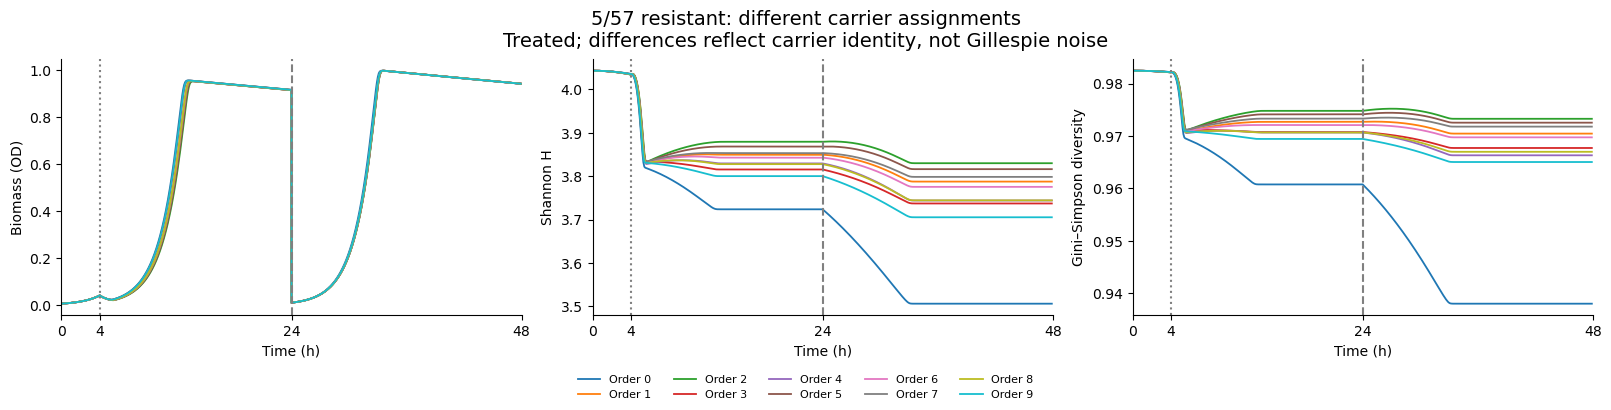

In [14]:
RESISTANT_COUNT = 5
TREATED = True

v_selected_curves = v_curves[
    v_curves.n_resistant.eq(RESISTANT_COUNT)
    & v_curves.treated.eq(TREATED)
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")

for order, group in v_selected_curves.groupby("order_id"):
    group = group.sort_values("record_index")

    for ax, metric in zip(axes, ["biomass", "shannon", "simpson"]):
        ax.plot(
            np.maximum.accumulate(group.hour),
            group[metric],
            color=v_colors[order],
            linewidth=1.3,
            label=f"Order {order}" if order >= 0 else "Shared reference"
        )

for ax, label in zip(
    axes,
    ["Biomass (OD)", "Shannon H", "Gini–Simpson diversity"]
):
    ax.set(
        xlabel="Time (h)", ylabel=label,
        xlim=(0, 48), xticks=[0, 4, 24, 48]
    )
    ax.axvline(4, color="gray", linestyle=":")
    ax.axvline(24, color="gray", linestyle="--")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="outside lower center",
    ncol=5, frameon=False, fontsize=8
)
fig.suptitle(
    f"{RESISTANT_COUNT}/57 resistant: different carrier assignments\n"
    + ("Treated" if TREATED else "Untreated")
    + "; differences reflect carrier identity, not Gillespie noise",
    fontsize=14
)
plt.show()

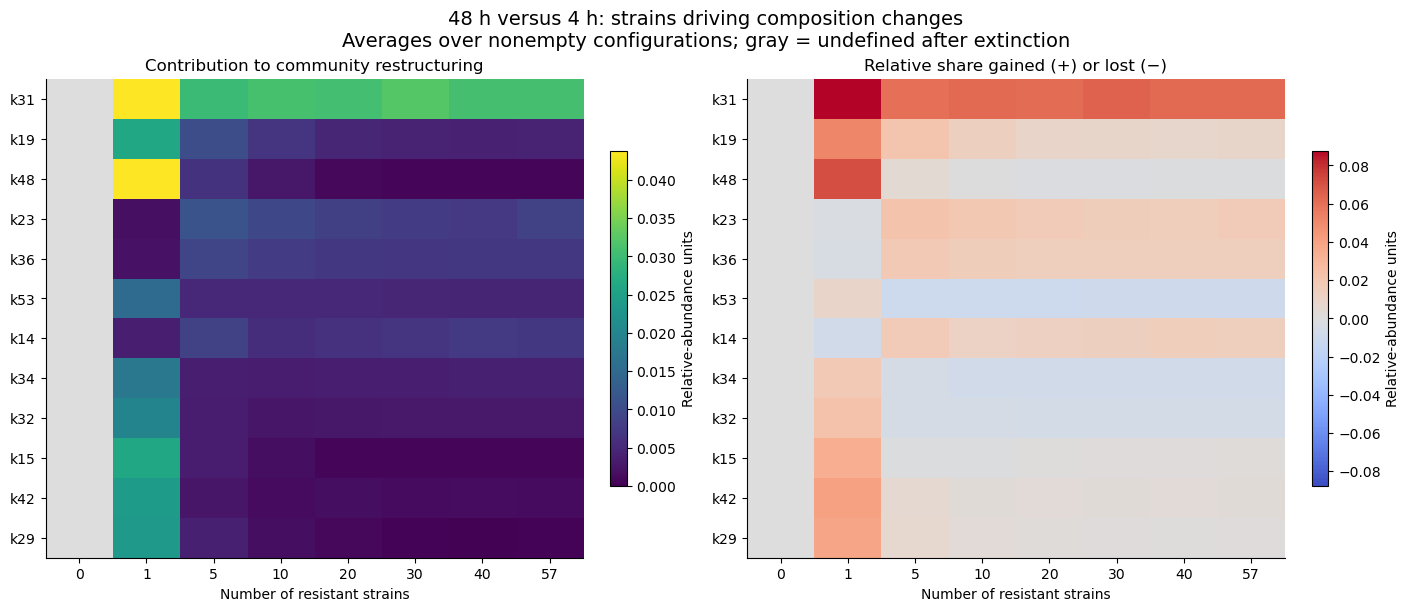

BC_contribution  signed_shift
strain n_resistant                               
k01    0                        NaN           NaN
       1                     0.0028        0.0040
       5                     0.0031        0.0063
       10                    0.0013        0.0027
       20                    0.0006        0.0013
...                             ...           ...
k57    10                    0.0031       -0.0061
       20                    0.0026       -0.0051
       30                    0.0027       -0.0054
       40                    0.0027       -0.0054
       57                    0.0026       -0.0053

[456 rows x 2 columns]

In [17]:
POST_HOUR = 48
v_species_rows = []

for d in design.itertuples():
    sim = RUNS[(d.scenario, True)]

    initial = sim["N"][v_sample(sim, BASELINE_HOUR)]
    final = sim["N"][v_sample(sim, POST_HOUR)]

    if initial.sum() > 0 and final.sum() > 0:
        delta = final / final.sum() - initial / initial.sum()
    else:
        delta = np.full(57, np.nan)

    for name, change in zip(v_names, delta):
        v_species_rows.append({
            "scenario": d.scenario,
            "n_resistant": d.n_resistant,
            "strain": name,
            "signed_shift": change,
            "BC_contribution": 0.5 * abs(change),
        })

v_species = pd.DataFrame(v_species_rows)

# Descriptive ranking across saved, nonempty configurations.
v_leaders = (
    v_species.groupby("strain").BC_contribution.mean()
    .nlargest(12).index.tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")

for ax, metric, title, cmap in zip(
    axes,
    ["BC_contribution", "signed_shift"],
    [
        "Contribution to community restructuring",
        "Relative share gained (+) or lost (−)"
    ],
    ["viridis", "coolwarm"]
):
    table = (
        v_species.groupby(["strain", "n_resistant"])[metric]
        .mean().unstack()
        .reindex(index=v_leaders, columns=v_counts)
    )

    values = table.to_numpy()
    finite = values[np.isfinite(values)]
    limit = max(np.max(abs(finite)), 1e-9) if len(finite) else 1

    color_map = plt.get_cmap(cmap).copy()
    color_map.set_bad("#dddddd")

    image = ax.imshow(
        np.ma.masked_invalid(values),
        aspect="auto", cmap=color_map,
        vmin=-limit if metric == "signed_shift" else 0,
        vmax=limit
    )

    ax.set_xticks(range(len(v_counts)), v_counts)
    ax.set_yticks(range(len(v_leaders)), v_leaders)
    ax.set(title=title, xlabel="Number of resistant strains")
    fig.colorbar(
        image, ax=ax, shrink=0.7,
        label="Relative-abundance units"
    )

fig.suptitle(
    f"{POST_HOUR} h versus {BASELINE_HOUR} h: strains driving composition changes\n"
    "Averages over nonempty configurations; gray = undefined after extinction",
    fontsize=14
)
plt.show()

# Optional: inspect the exact values.
display(
    v_species.groupby(["strain", "n_resistant"])
    [["BC_contribution", "signed_shift"]].mean().round(4)
)

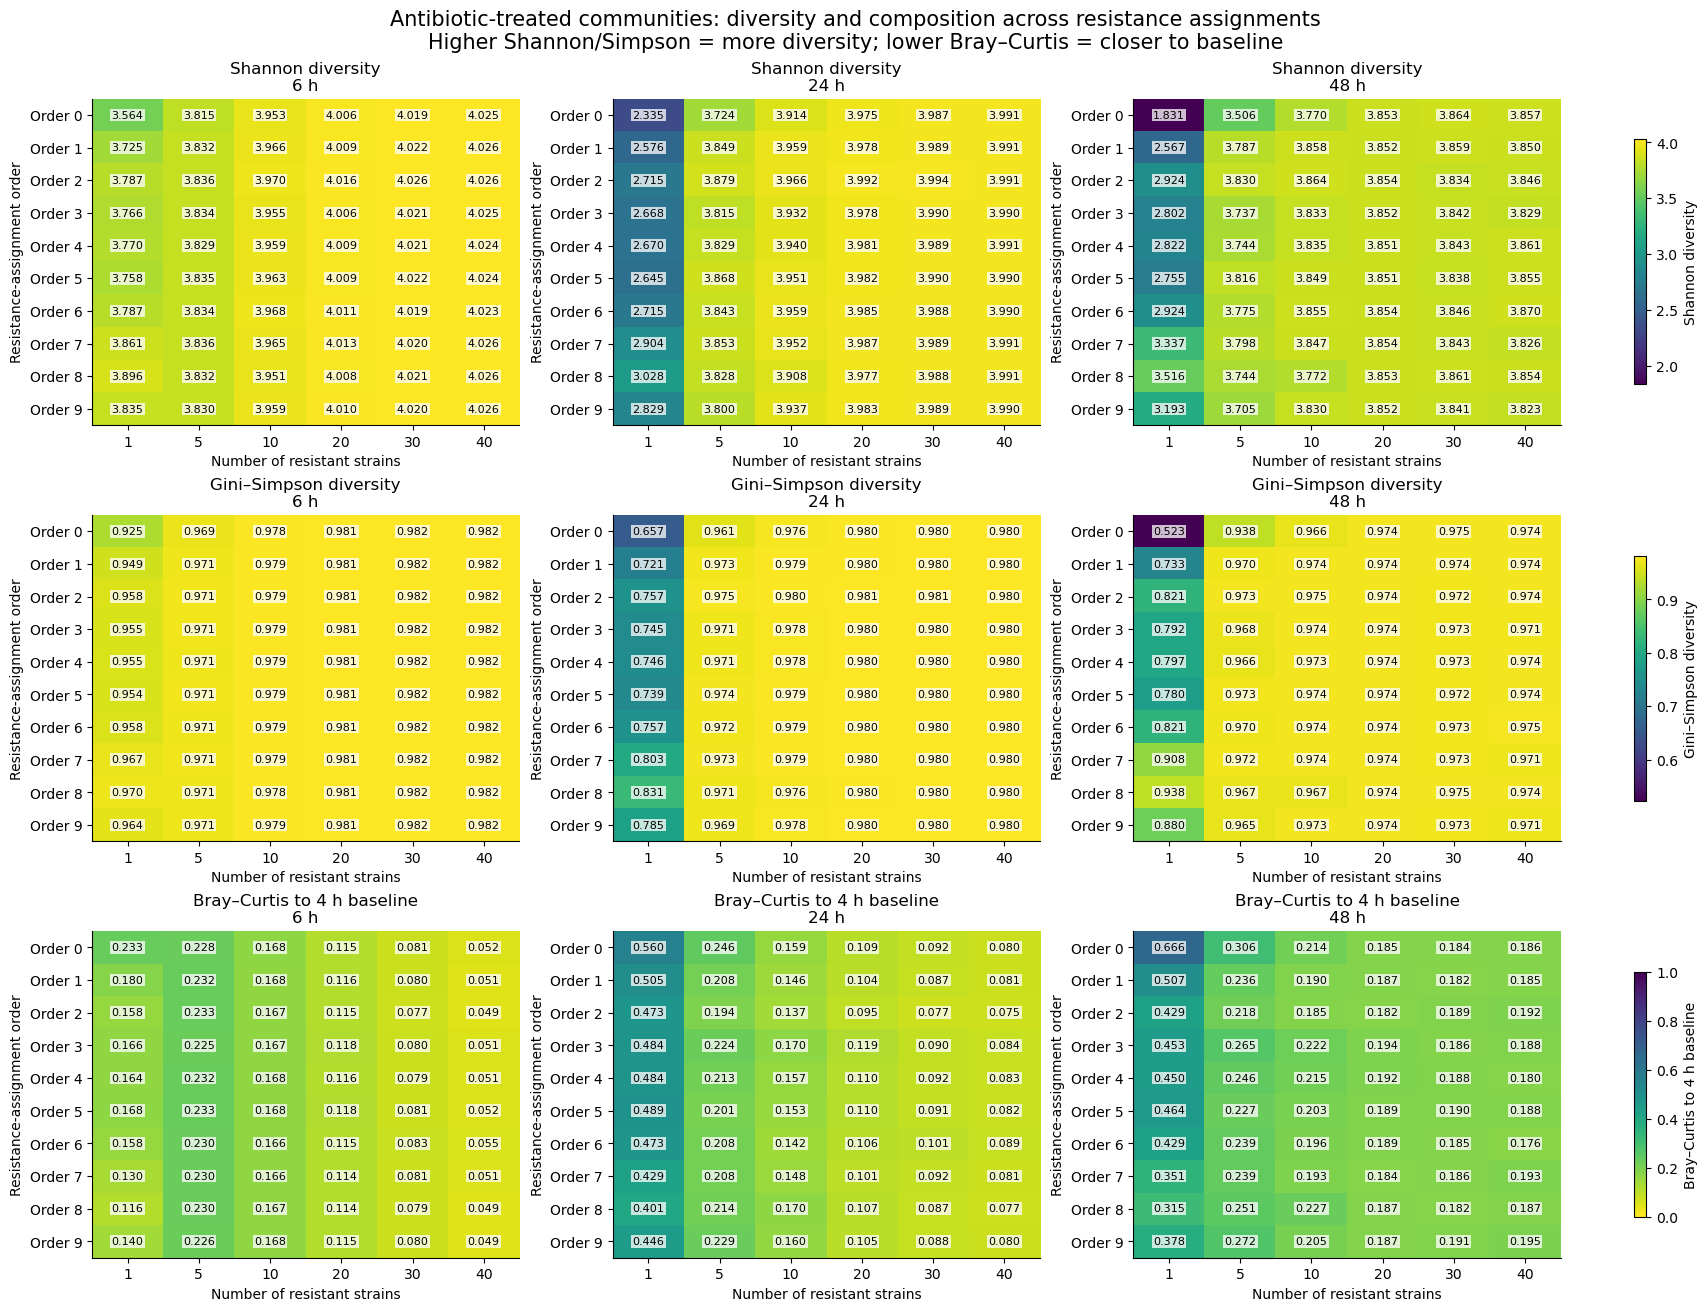

Shared references: 0 and 57 resistant strains have no alternative assignments.


,n_resistant,hour,biomass,shannon,simpson,bray_curtis
607,0,6,0.0085,4.0421,0.9824,0.0390
608,0,24,0.0000,NaN,NaN,NaN
609,0,48,0.0000,NaN,NaN,NaN
617,57,6,0.0984,4.0266,0.9819,0.0241
618,57,24,0.9454,3.9907,0.9805,0.0791
619,57,48,0.9447,3.8533,0.9737,0.1870


In [18]:
import numpy as np
import matplotlib.pyplot as plt

TREATED = True
HEATMAP_HOURS = [6, 24, 48]

# The zero/all-resistant configurations have only one assignment.
# Keep them separate rather than repeating them across all order rows.
heatmap_counts = [k for k in v_counts if 0 < k < 57]

heatmap_metrics = [
    ("shannon", "Shannon diversity", "viridis"),
    ("simpson", "Gini–Simpson diversity", "viridis"),
    (
        "bray_curtis",
        f"Bray–Curtis to {BASELINE_HOUR} h baseline",
        "viridis_r"
    ),
]

selected = v_samples[
    v_samples.treated.eq(TREATED)
    & ~v_samples.reference
    & v_samples.hour.isin(HEATMAP_HOURS)
].copy()

fig, axes = plt.subplots(
    3, len(HEATMAP_HOURS),
    figsize=(17, 13),
    squeeze=False,
    layout="constrained"
)

for row, (metric, title, cmap_name) in enumerate(heatmap_metrics):
    # Same color scale across time points for each metric.
    finite = selected.loc[np.isfinite(selected[metric]), metric]

    if metric == "bray_curtis":
        lower, upper = 0, 1
    elif len(finite):
        lower, upper = finite.min(), finite.max()
        if np.isclose(lower, upper):
            lower -= 0.01
            upper += 0.01
    else:
        lower, upper = 0, 1

    color_map = plt.get_cmap(cmap_name).copy()
    color_map.set_bad("#dddddd")

    for col, hour in enumerate(HEATMAP_HOURS):
        ax = axes[row, col]
        data = selected[selected.hour.eq(hour)]

        table = data.pivot(
            index="order_id",
            columns="n_resistant",
            values=metric
        ).reindex(
            index=v_orders,
            columns=heatmap_counts
        )

        values = table.to_numpy(dtype=float)

        image = ax.imshow(
            np.ma.masked_invalid(values),
            aspect="auto",
            cmap=color_map,
            vmin=lower,
            vmax=upper
        )

        ax.set_xticks(range(len(heatmap_counts)), heatmap_counts)
        ax.set_yticks(
            range(len(v_orders)),
            [f"Order {order}" for order in v_orders]
        )
        ax.set_xlabel("Number of resistant strains")
        ax.set_ylabel("Resistance-assignment order")
        ax.set_title(f"{title}\n{hour} h")

        # Display the actual value inside each cell.
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                value = values[i, j]
                label = f"{value:.3f}" if np.isfinite(value) else "Undefined"

                ax.text(
                    j, i, label,
                    ha="center", va="center",
                    fontsize=8, color="black",
                    bbox={
                        "facecolor": "white",
                        "alpha": 0.75,
                        "edgecolor": "none",
                        "pad": 1
                    }
                )

    fig.colorbar(
        image,
        ax=axes[row, :].tolist(),
        shrink=0.75,
        label=title
    )

fig.suptitle(
    ("Antibiotic-treated" if TREATED else "Untreated")
    + " communities: diversity and composition across resistance assignments\n"
    "Higher Shannon/Simpson = more diversity; lower Bray–Curtis = closer to baseline",
    fontsize=15
)

plt.show()

# Shared endpoint references are displayed once in a separate table.
reference_values = v_samples[
    v_samples.treated.eq(TREATED)
    & v_samples.reference
    & v_samples.hour.isin(HEATMAP_HOURS)
][[
    "n_resistant", "hour", "biomass",
    "shannon", "simpson", "bray_curtis"
]].sort_values(["n_resistant", "hour"])

print("Shared references: 0 and 57 resistant strains have no alternative assignments.")
display(reference_values.round(4))

### Shannon diversity
Shannon measures diversity based on both the number of strains present and how evenly their abundances are distributed. It is more sensitive to low-abundance strains than Gini–Simpson.

- **0:** Only one strain is present.
- **Maximum in our model: ln(57) ≈ 4.04:** All 57 strains are equally abundant.
- **Higher values indicate greater diversity.** The value is not a percentage.

### Gini–Simpson diversity
Gini–Simpson measures the probability that two independently selected cells belong to different strains. It emphasizes common strains and whether a few strains dominate.

- **0:** Only one strain is present.
- **Maximum in our model: 1 − 1/57 ≈ 0.982:** All 57 strains are equally abundant.
- **Higher values indicate greater diversity.** A value of 0.90 means a 90% probability of selecting two cells from different strains.

### Bray–Curtis dissimilarity
Bray–Curtis measures how much the relative strain composition differs from a reference community. Here, each community is compared with its own composition at **4 hours, immediately before antibiotic addition**.

- **0:** Identical relative strain proportions.
- **1:** No strains shared between the two communities.
- **Higher values indicate greater compositional change**, not necessarily lower diversity.

### Shannon diversity retention
Shannon retention is Shannon diversity at a later time divided by its value at the 4-hour pretreatment baseline.

- **1:** Diversity is unchanged.
- **Below 1:** Diversity is lower than baseline.
- **Above 1:** Diversity is higher than baseline.
- A value of **0.80** means the Shannon index is 80% of its baseline value—not that 80% of strains survived.

**Note:** If the community is completely extinct, diversity and relative-composition metrics are undefined. Shannon retention is also undefined when baseline Shannon diversity is zero.

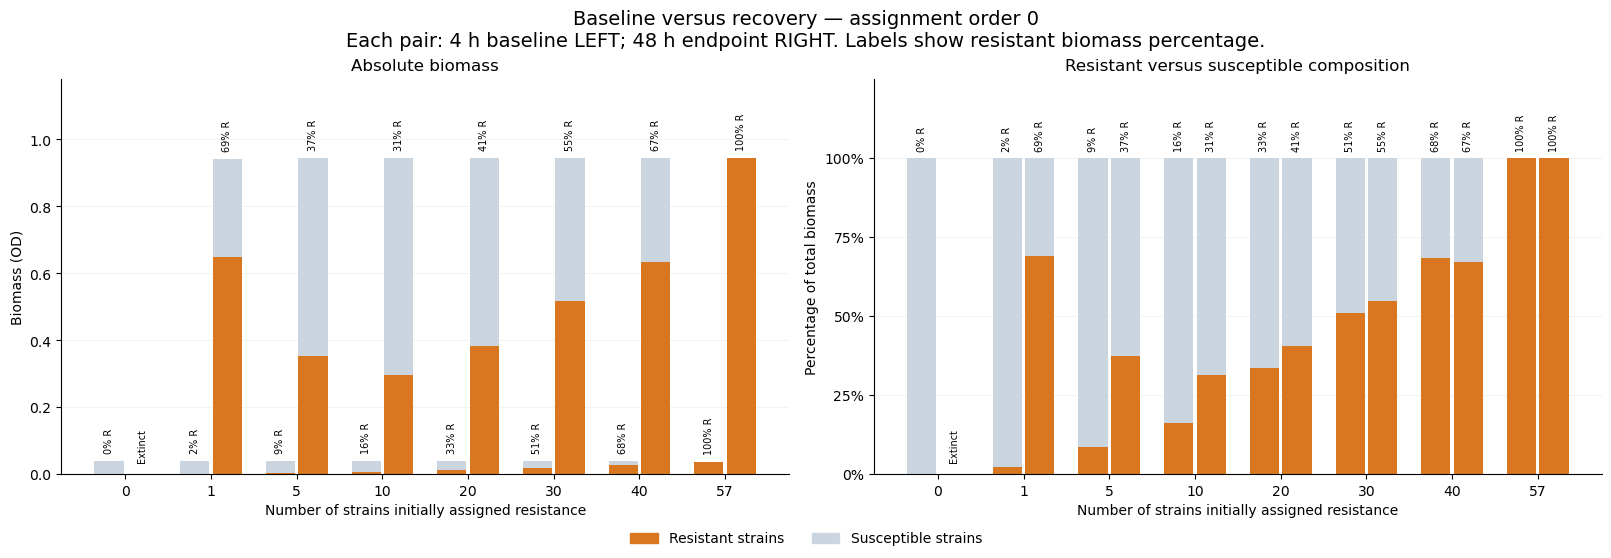

,n_resistant,requested_hour,actual_hour,resistant_biomass,susceptible_biomass,total_biomass,resistant_fraction,susceptible_fraction
0,0,4,4.0,0.000000,0.040425,0.040425,0.000000,1.000000
1,0,48,47.9,0.000000,0.000000,0.000000,NaN,NaN
2,1,4,4.0,0.000908,0.039398,0.040305,0.022524,0.977476
3,1,48,47.9,0.648967,0.292911,0.941878,0.689014,0.310986
4,5,4,4.0,0.003458,0.036562,0.040020,0.086410,0.913590
5,5,48,47.9,0.351619,0.591596,0.943215,0.372787,0.627213
6,10,4,4.0,0.006471,0.033224,0.039696,0.163023,0.836977
7,10,48,47.9,0.296134,0.647418,0.943553,0.313850,0.686150
8,20,4,4.0,0.013011,0.025949,0.038960,0.333956,0.666045
9,20,48,47.9,0.383614,0.560221,0.943835,0.406442,0.593558


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

ORDER_TO_SHOW = 0
TREATED = True
COMPARE_HOURS = [4, 48]

R_COLOR = "#d97720"
S_COLOR = "#cbd5df"

selected_design = design[
    design.order_id.eq(ORDER_TO_SHOW) | design.reference
].sort_values("n_resistant")

# Calculate resistant/susceptible biomass from the actual simulated populations.
resistance_rows = []

for d in selected_design.itertuples():
    sim = RUNS[(d.scenario, TREATED)]
    carrier = np.asarray(sim["carrier"], dtype=bool)

    for hour in COMPARE_HOURS:
        index = v_sample(sim, hour)
        abundance = sim["N"][index]

        resistant = float(abundance[carrier].sum())
        susceptible = float(abundance[~carrier].sum())
        total = resistant + susceptible

        resistance_rows.append({
            "n_resistant": d.n_resistant,
            "requested_hour": hour,
            "actual_hour": float(sim["t"][index]),
            "resistant_biomass": resistant,
            "susceptible_biomass": susceptible,
            "total_biomass": total,
            "resistant_fraction": resistant / total if total > 0 else np.nan,
            "susceptible_fraction": susceptible / total if total > 0 else np.nan,
        })

resistance_comparison = pd.DataFrame(resistance_rows)

fig, axes = plt.subplots(
    1, 2, figsize=(16, 5.5), layout="constrained"
)

counts = selected_design.n_resistant.tolist()
positions = np.arange(len(counts))
width = 0.34
max_biomass = resistance_comparison.total_biomass.max()

for time_index, hour in enumerate(COMPARE_HOURS):
    group = (
        resistance_comparison[
            resistance_comparison.requested_hour.eq(hour)
        ]
        .set_index("n_resistant")
        .reindex(counts)
    )

    x = positions + (-0.19 if time_index == 0 else 0.19)

    # Absolute biomass: bar height is the actual total biomass.
    axes[0].bar(
        x, group.resistant_biomass, width,
        color=R_COLOR
    )
    axes[0].bar(
        x, group.susceptible_biomass, width,
        bottom=group.resistant_biomass,
        color=S_COLOR
    )

    # Relative composition: each nonempty community totals 100%.
    axes[1].bar(
        x, group.resistant_fraction, width,
        color=R_COLOR
    )
    axes[1].bar(
        x, group.susceptible_fraction, width,
        bottom=group.resistant_fraction,
        color=S_COLOR
    )

    for i, (_, row) in enumerate(group.iterrows()):
        if row.total_biomass > 0:
            # Label the percentage belonging to resistant strains.
            label = f"{row.resistant_fraction:.0%} R"

            axes[0].text(
                x[i],
                row.total_biomass + max_biomass * 0.025,
                label,
                ha="center", va="bottom", fontsize=7,
                rotation=90
            )
            axes[1].text(
                x[i], 1.02, label,
                ha="center", va="bottom", fontsize=7,
                rotation=90
            )
        else:
            for ax in axes:
                ax.text(
                    x[i], 0.03, "Extinct",
                    transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom",
                    rotation=90, fontsize=7
                )

for ax in axes:
    ax.set_xticks(positions, counts)
    ax.set_xlabel("Number of strains initially assigned resistance")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

axes[0].set(
    title="Absolute biomass",
    ylabel="Biomass (OD)",
    ylim=(0, max(max_biomass * 1.25, 0.01))
)

axes[1].set(
    title="Resistant versus susceptible composition",
    ylabel="Percentage of total biomass",
    ylim=(0, 1.25)
)
axes[1].set_yticks([0, 0.25, 0.5, 0.75, 1])
axes[1].yaxis.set_major_formatter(PercentFormatter(1))

fig.legend(
    handles=[
        Patch(color=R_COLOR, label="Resistant strains"),
        Patch(color=S_COLOR, label="Susceptible strains")
    ],
    loc="outside lower center",
    ncol=2, frameon=False
)

fig.suptitle(
    f"Baseline versus recovery — assignment order {ORDER_TO_SHOW}\n"
    f"Each pair: {COMPARE_HOURS[0]} h baseline LEFT; "
    f"{COMPARE_HOURS[1]} h endpoint RIGHT. "
    "Labels show resistant biomass percentage.",
    fontsize=14
)

plt.show()

# Exact values, including the actual saved sampling times.
display(resistance_comparison.round(7))

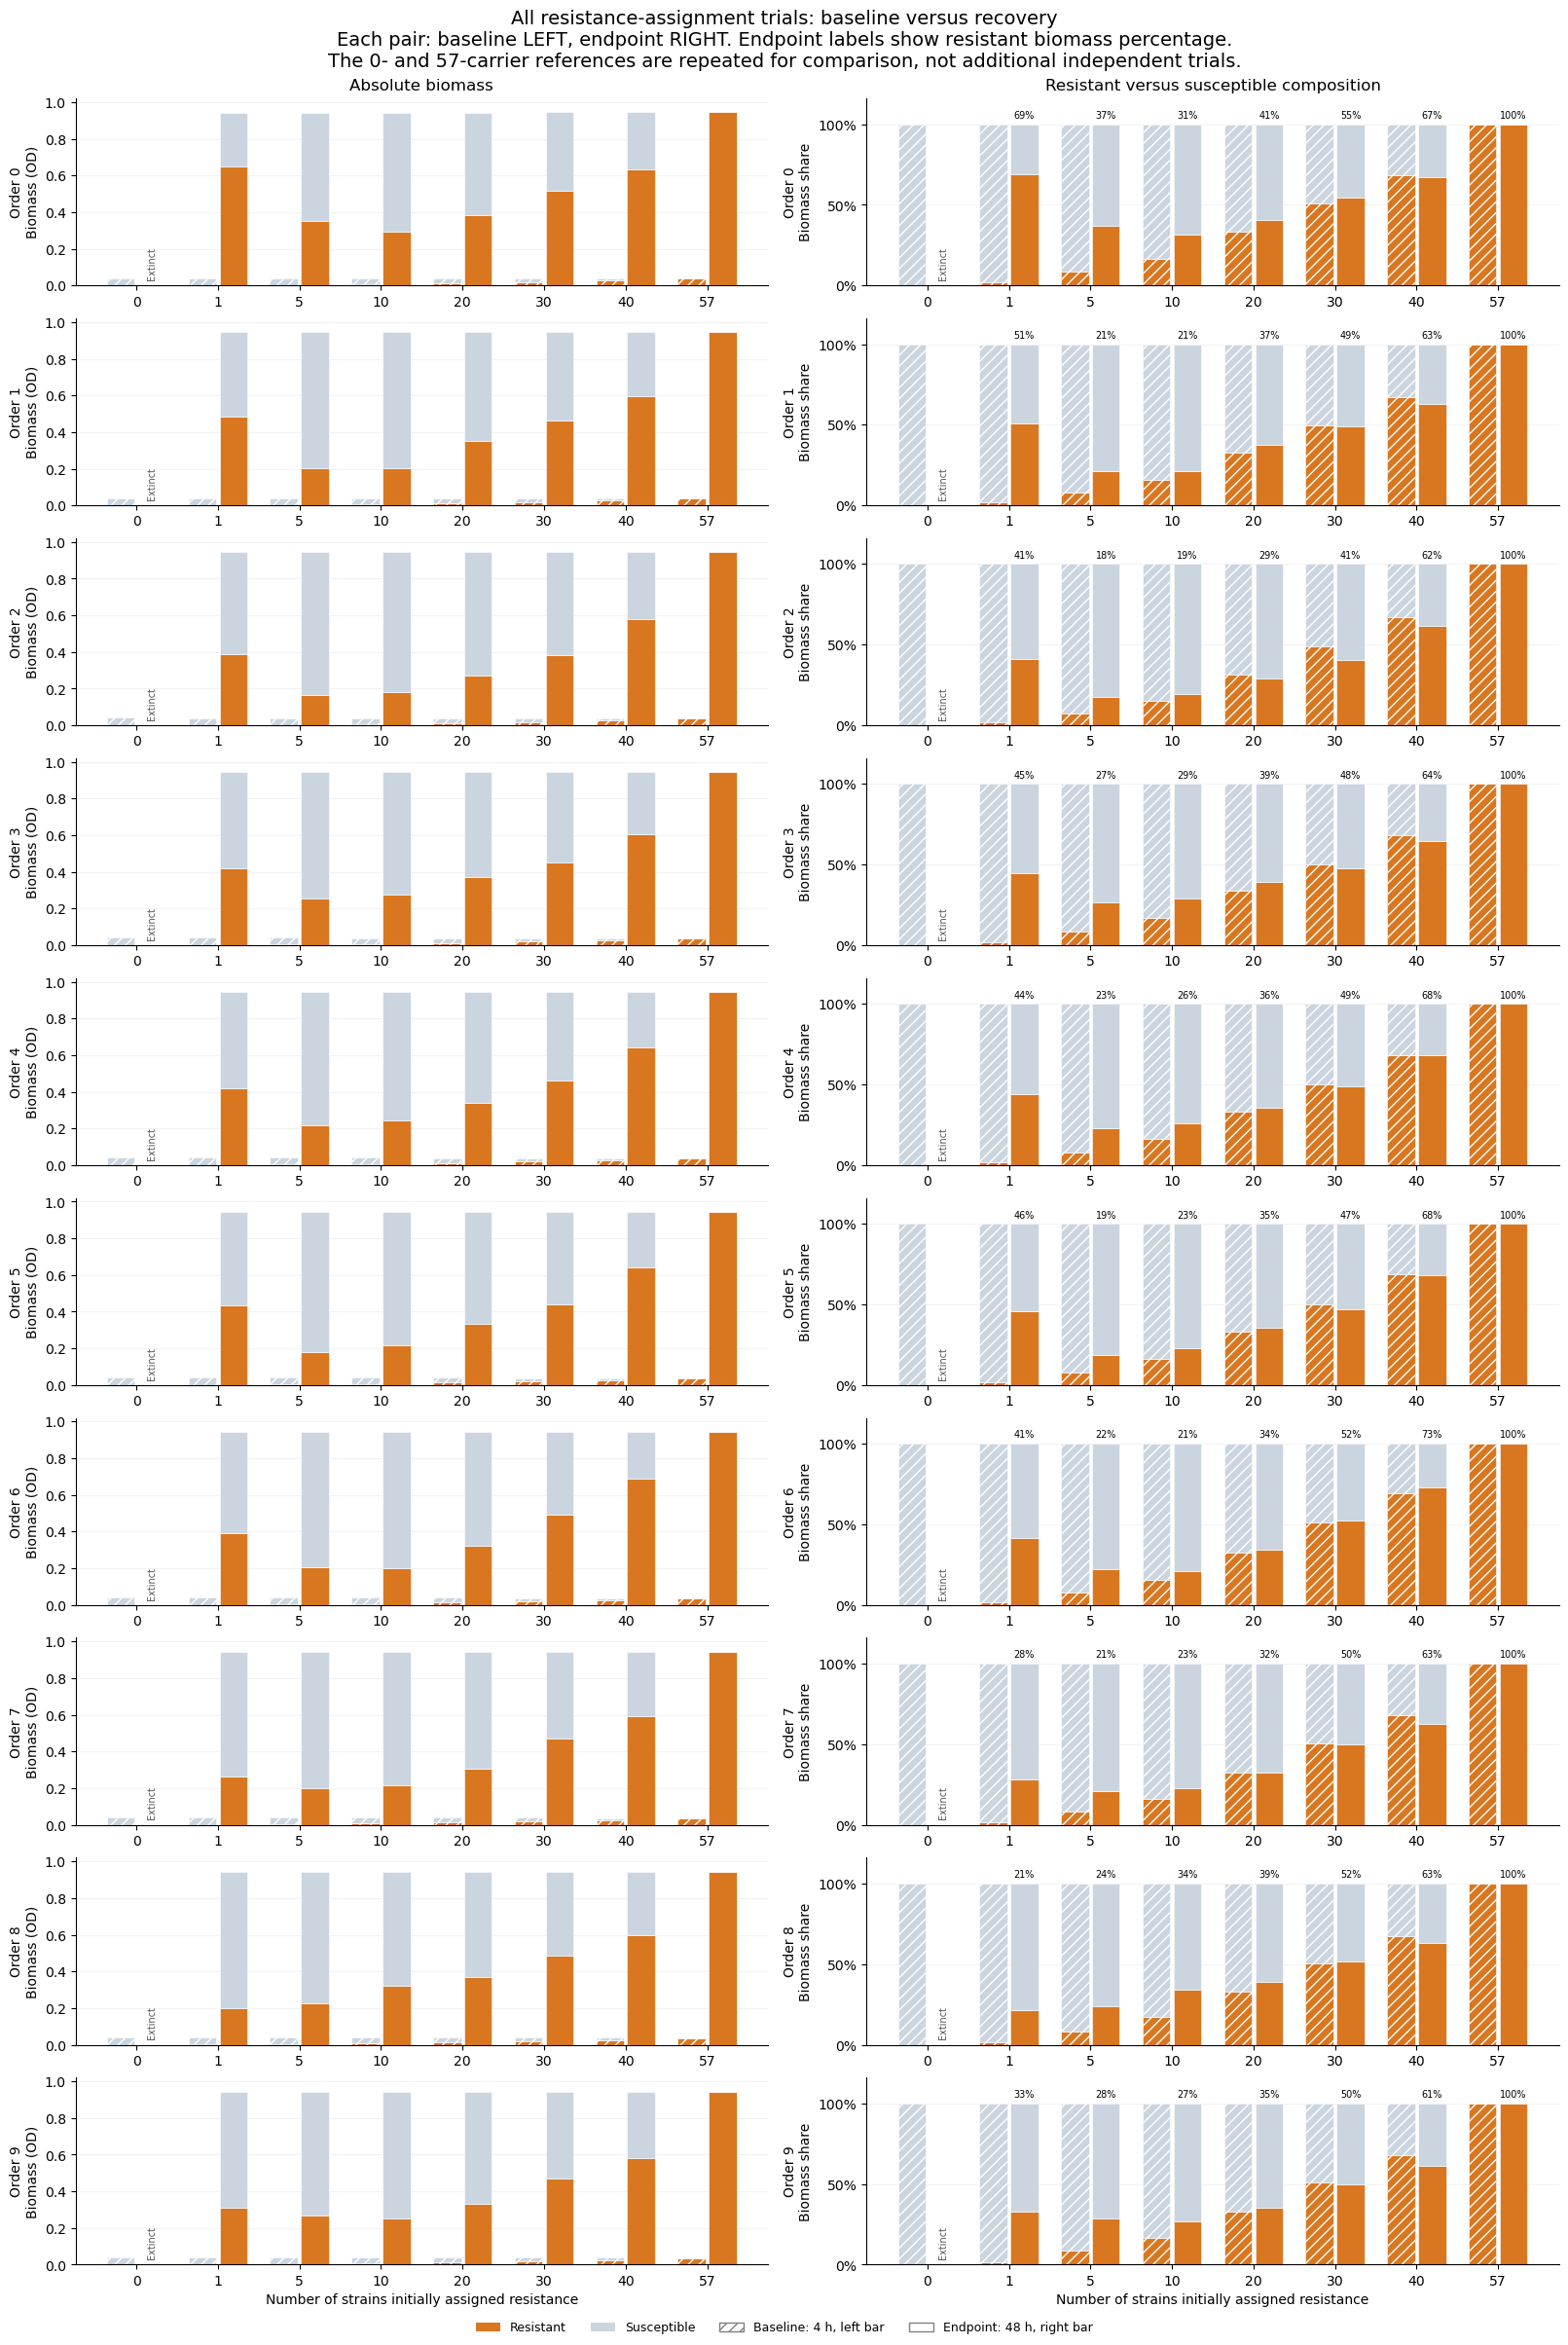

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

TREATED = True
BASELINE_TIME = 4
ENDPOINT_TIME = 48

R_COLOR = "#d97720"
S_COLOR = "#cbd5df"

orders_to_plot = sorted(
    design.loc[~design.reference, "order_id"].unique()
)
counts_to_plot = sorted(design.n_resistant.unique())

# Collect all trials, including the shared reference conditions.
all_rows = []

for order in orders_to_plot:
    selected_design = design[
        design.order_id.eq(order) | design.reference
    ].sort_values("n_resistant")

    for d in selected_design.itertuples():
        sim = RUNS[(d.scenario, TREATED)]
        carrier = np.asarray(sim["carrier"], dtype=bool)

        for hour in [BASELINE_TIME, ENDPOINT_TIME]:
            index = v_sample(sim, hour)
            abundance = sim["N"][index]

            resistant = float(abundance[carrier].sum())
            susceptible = float(abundance[~carrier].sum())
            total = resistant + susceptible

            all_rows.append({
                "order_id": order,
                "n_resistant": d.n_resistant,
                "reference": d.reference,
                "requested_hour": hour,
                "actual_hour": float(sim["t"][index]),
                "resistant_biomass": resistant,
                "susceptible_biomass": susceptible,
                "total_biomass": total,
                "resistant_fraction": (
                    resistant / total if total > 0 else np.nan
                ),
            })

all_resistance_comparisons = pd.DataFrame(all_rows)

fig, axes = plt.subplots(
    len(orders_to_plot), 2,
    figsize=(16, 2.2 * len(orders_to_plot) + 2),
    sharex=True,
    sharey="col",
    squeeze=False,
    layout="constrained"
)

positions = np.arange(len(counts_to_plot))
width = 0.34
maximum_biomass = all_resistance_comparisons.total_biomass.max()

for row, order in enumerate(orders_to_plot):
    for hour, offset, hatch in [
        (BASELINE_TIME, -0.19, "///"),
        (ENDPOINT_TIME, 0.19, None)
    ]:
        data = (
            all_resistance_comparisons[
                all_resistance_comparisons.order_id.eq(order)
                & all_resistance_comparisons.requested_hour.eq(hour)
            ]
            .set_index("n_resistant")
            .reindex(counts_to_plot)
        )

        x = positions + offset

        # LEFT: actual resistant and susceptible biomass.
        axes[row, 0].bar(
            x, data.resistant_biomass, width,
            color=R_COLOR, hatch=hatch,
            edgecolor="white", linewidth=0.4
        )
        axes[row, 0].bar(
            x, data.susceptible_biomass, width,
            bottom=data.resistant_biomass,
            color=S_COLOR, hatch=hatch,
            edgecolor="white", linewidth=0.4
        )

        # RIGHT: normalize each nonempty community to 100%.
        axes[row, 1].bar(
            x, data.resistant_fraction, width,
            color=R_COLOR, hatch=hatch,
            edgecolor="white", linewidth=0.4
        )
        axes[row, 1].bar(
            x, 1 - data.resistant_fraction, width,
            bottom=data.resistant_fraction,
            color=S_COLOR, hatch=hatch,
            edgecolor="white", linewidth=0.4
        )

        for i, (_, record) in enumerate(data.iterrows()):
            if record.total_biomass <= 0:
                for ax in axes[row]:
                    ax.text(
                        x[i], 0.03, "Extinct",
                        transform=ax.get_xaxis_transform(),
                        rotation=90, ha="center", va="bottom",
                        fontsize=7, color="#555555"
                    )

            elif hour == ENDPOINT_TIME:
                # Label the endpoint's resistant percentage.
                axes[row, 1].text(
                    x[i], 1.025,
                    f"{record.resistant_fraction:.0%}",
                    ha="center", va="bottom", fontsize=7
                )

    axes[row, 0].set_ylabel(f"Order {order}\nBiomass (OD)")
    axes[row, 1].set_ylabel(f"Order {order}\nBiomass share")

    axes[row, 0].set_ylim(
        0, max(maximum_biomass * 1.08, 0.01)
    )
    axes[row, 1].set_ylim(0, 1.16)
    axes[row, 1].set_yticks([0, 0.5, 1])
    axes[row, 1].yaxis.set_major_formatter(PercentFormatter(1))

    for ax in axes[row]:
        ax.set_xticks(positions, counts_to_plot)
        ax.tick_params(labelbottom=True)
        ax.grid(axis="y", alpha=0.15)
        ax.set_axisbelow(True)

axes[0, 0].set_title("Absolute biomass")
axes[0, 1].set_title("Resistant versus susceptible composition")

for ax in axes[-1]:
    ax.set_xlabel("Number of strains initially assigned resistance")

fig.legend(
    handles=[
        Patch(facecolor=R_COLOR, label="Resistant"),
        Patch(facecolor=S_COLOR, label="Susceptible"),
        Patch(
            facecolor="white", edgecolor="gray",
            hatch="///", label=f"Baseline: {BASELINE_TIME} h, left bar"
        ),
        Patch(
            facecolor="white", edgecolor="gray",
            label=f"Endpoint: {ENDPOINT_TIME} h, right bar"
        ),
    ],
    loc="outside lower center",
    ncol=4, frameon=False, fontsize=9
)

fig.suptitle(
    "All resistance-assignment trials: baseline versus recovery\n"
    "Each pair: baseline LEFT, endpoint RIGHT. "
    "Endpoint labels show resistant biomass percentage.\n"
    "The 0- and 57-carrier references are repeated for comparison, "
    "not additional independent trials.",
    fontsize=14
)

plt.show()

# Optional: save a high-resolution copy.
# fig.savefig("all_trials_resistance_comparison.png",
#             dpi=300, bbox_inches="tight")

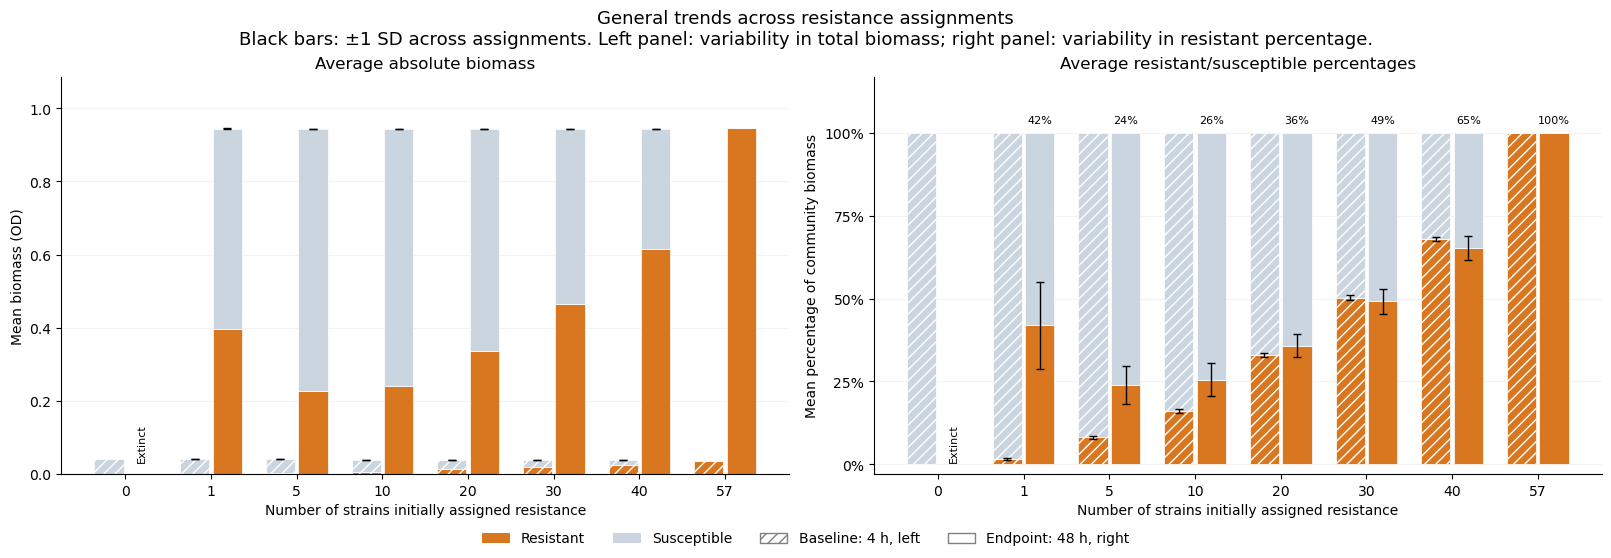

,n_resistant,requested_hour,mean_resistant,mean_susceptible,mean_total,sd_total,mean_resistant_fraction,sd_resistant_fraction,n_communities,n_nonempty
0,0,4,0.0000,0.0404,0.0404,NaN,0.0000,NaN,1,1
1,0,48,0.0000,0.0000,0.0000,NaN,NaN,NaN,1,0
2,1,4,0.0007,0.0397,0.0403,0.0000,0.0164,0.0027,10,10
3,1,48,0.3958,0.5481,0.9439,0.0008,0.4194,0.1311,10,10
4,5,4,0.0032,0.0368,0.0401,0.0000,0.0804,0.0039,10,10
5,5,48,0.2265,0.7170,0.9436,0.0001,0.2401,0.0572,10,10
6,10,4,0.0064,0.0333,0.0397,0.0000,0.1613,0.0063,10,10
7,10,48,0.2409,0.7027,0.9436,0.0000,0.2553,0.0489,10,10
8,20,4,0.0128,0.0262,0.0390,0.0000,0.3286,0.0066,10,10
9,20,48,0.3374,0.6064,0.9438,0.0000,0.3575,0.0349,10,10


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

# Remove repeated displays of the shared 0- and 57-carrier references.
average_input = all_resistance_comparisons.copy()

references = (
    average_input[average_input.reference]
    .drop_duplicates(["n_resistant", "requested_hour"])
)
intermediate = average_input[~average_input.reference]

average_input = pd.concat(
    [intermediate, references], ignore_index=True
)

summary = (
    average_input
    .groupby(["n_resistant", "requested_hour"])
    .agg(
        mean_resistant=("resistant_biomass", "mean"),
        mean_susceptible=("susceptible_biomass", "mean"),
        mean_total=("total_biomass", "mean"),
        sd_total=("total_biomass", "std"),
        mean_resistant_fraction=("resistant_fraction", "mean"),
        sd_resistant_fraction=("resistant_fraction", "std"),
        n_communities=("total_biomass", "size"),
        n_nonempty=("resistant_fraction", "count"),
    )
    .reset_index()
)

counts = sorted(summary.n_resistant.unique())
positions = np.arange(len(counts))
width = 0.34

fig, axes = plt.subplots(
    1, 2, figsize=(16, 5.5), layout="constrained"
)

for hour, offset, hatch in [
    (BASELINE_TIME, -0.19, "///"),
    (ENDPOINT_TIME, 0.19, None)
]:
    data = (
        summary[summary.requested_hour.eq(hour)]
        .set_index("n_resistant")
        .reindex(counts)
    )
    x = positions + offset

    # Average absolute biomass, including extinct communities as zero biomass.
    axes[0].bar(
        x, data.mean_resistant, width,
        color=R_COLOR, hatch=hatch,
        edgecolor="white", linewidth=0.5
    )
    axes[0].bar(
        x, data.mean_susceptible, width,
        bottom=data.mean_resistant,
        color=S_COLOR, hatch=hatch,
        edgecolor="white", linewidth=0.5
    )

    valid = data.sd_total.notna()
    axes[0].errorbar(
        x[valid], data.loc[valid, "mean_total"],
        yerr=data.loc[valid, "sd_total"],
        fmt="none", color="black", capsize=3, linewidth=1
    )

    # Average community percentages; composition is undefined after extinction.
    axes[1].bar(
        x, data.mean_resistant_fraction, width,
        color=R_COLOR, hatch=hatch,
        edgecolor="white", linewidth=0.5
    )
    axes[1].bar(
        x, 1 - data.mean_resistant_fraction, width,
        bottom=data.mean_resistant_fraction,
        color=S_COLOR, hatch=hatch,
        edgecolor="white", linewidth=0.5
    )

    valid = data.sd_resistant_fraction.notna()
    axes[1].errorbar(
        x[valid], data.loc[valid, "mean_resistant_fraction"],
        yerr=data.loc[valid, "sd_resistant_fraction"],
        fmt="none", color="black", capsize=3, linewidth=1
    )

    for i, (_, record) in enumerate(data.iterrows()):
        if record.n_nonempty == 0:
            for ax in axes:
                ax.text(
                    x[i], 0.03, "Extinct",
                    transform=ax.get_xaxis_transform(),
                    rotation=90, ha="center", va="bottom",
                    fontsize=8
                )
        elif hour == ENDPOINT_TIME:
            axes[1].text(
                x[i], 1.03,
                f"{record.mean_resistant_fraction:.0%}",
                ha="center", fontsize=8
            )

for ax in axes:
    ax.set_xticks(positions, counts)
    ax.set_xlabel("Number of strains initially assigned resistance")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

axes[0].set(
    title="Average absolute biomass",
    ylabel="Mean biomass (OD)"
)
axes[0].set_ylim(
    0,
    max(
        (summary.mean_total + summary.sd_total.fillna(0)).max() * 1.15,
        0.01
    )
)

axes[1].set(
    title="Average resistant/susceptible percentages",
    ylabel="Mean percentage of community biomass",
    ylim=(-0.03, 1.17)
)
axes[1].set_yticks([0, 0.25, 0.5, 0.75, 1])
axes[1].yaxis.set_major_formatter(PercentFormatter(1))

fig.legend(
    handles=[
        Patch(facecolor=R_COLOR, label="Resistant"),
        Patch(facecolor=S_COLOR, label="Susceptible"),
        Patch(
            facecolor="white", edgecolor="gray",
            hatch="///", label=f"Baseline: {BASELINE_TIME} h, left"
        ),
        Patch(
            facecolor="white", edgecolor="gray",
            label=f"Endpoint: {ENDPOINT_TIME} h, right"
        ),
    ],
    loc="outside lower center",
    ncol=4, frameon=False
)

fig.suptitle(
    "General trends across resistance assignments\n"
    "Black bars: ±1 SD across assignments. "
    "Left panel: variability in total biomass; "
    "right panel: variability in resistant percentage.",
    fontsize=13
)

plt.show()
display(summary.round(4))

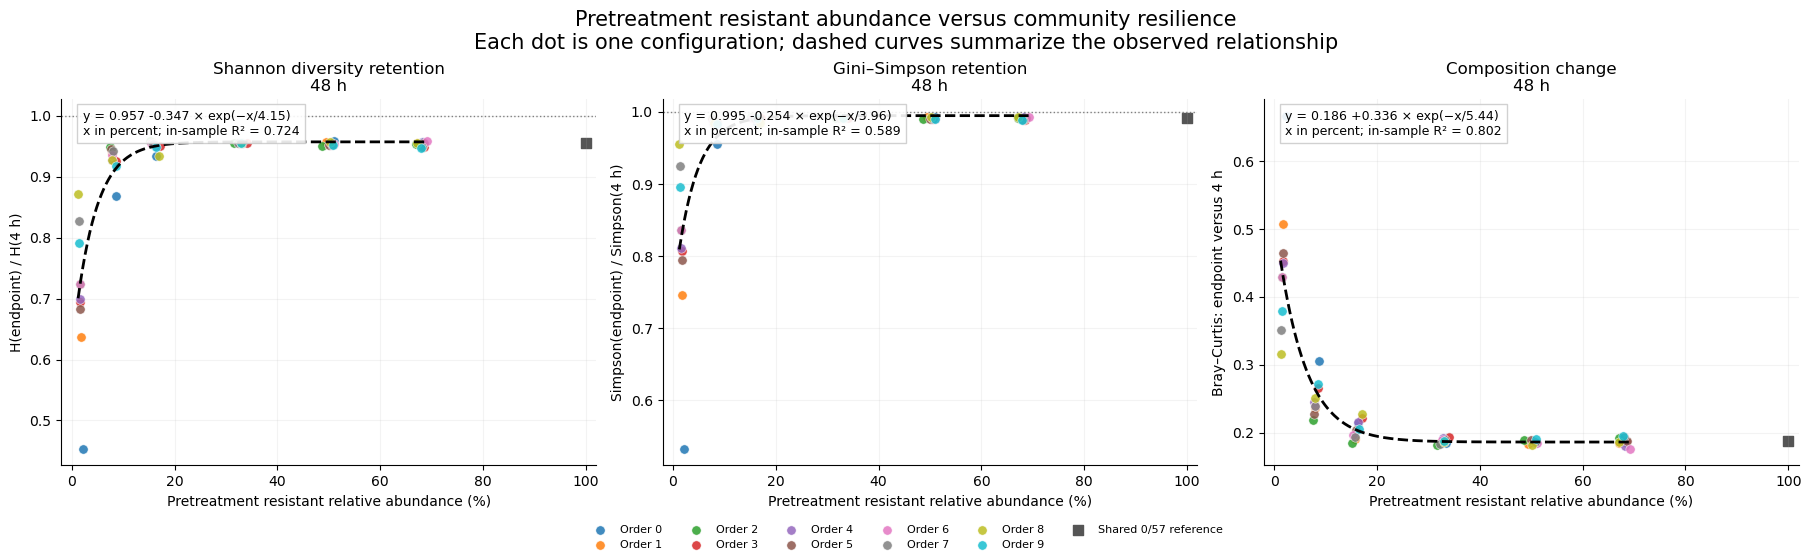

,metric,plateau_c,amplitude_A,K_percentage_points,in_sample_R_squared,n_configurations
0,shannon_retention,0.95699,-0.34662,4.15016,0.72386,60
1,simpson_retention,0.99452,-0.25445,3.95586,0.58940,60
2,bray_curtis,0.18598,0.33604,5.43805,0.80170,60


Undefined outcomes after extinction are omitted from the plots, not assigned zero diversity or dissimilarity.


,scenario,order_id,reference,resistant_percent,shannon_retention,simpson_retention,bray_curtis,extinct
60,reference_k00,-1,True,0.0,NaN,NaN,NaN,True


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

ENDPOINT_HOUR = 48
PRETREATMENT_HOUR = 4

# Calculate the predictor and outcomes from each treated simulation.
abundance_rows = []

for d in design.itertuples():
    sim = RUNS[(d.scenario, True)]
    carrier = np.asarray(sim["carrier"], dtype=bool)

    baseline = sim["N"][v_sample(sim, PRETREATMENT_HOUR)]
    endpoint = sim["N"][v_sample(sim, ENDPOINT_HOUR)]

    def get_diversity(x):
        if x.sum() <= 0:
            return np.nan, np.nan
        p = x / x.sum()
        positive = p > 0
        return (
            float(-(p[positive] * np.log(p[positive])).sum()),
            float(1 - np.sum(p**2))
        )

    H0, S0 = get_diversity(baseline)
    H1, S1 = get_diversity(endpoint)

    resistant_percent = (
        100 * baseline[carrier].sum() / baseline.sum()
        if baseline.sum() > 0 else np.nan
    )

    BC = (
        0.5 * np.abs(
            endpoint / endpoint.sum() - baseline / baseline.sum()
        ).sum()
        if endpoint.sum() > 0 and baseline.sum() > 0
        else np.nan
    )

    abundance_rows.append({
        "scenario": d.scenario,
        "order_id": d.order_id,
        "reference": d.reference,
        "resistant_percent": resistant_percent,
        "shannon_retention": H1 / H0 if H0 > 0 else np.nan,
        "simpson_retention": S1 / S0 if S0 > 0 else np.nan,
        "bray_curtis": BC,
        "extinct": endpoint.sum() <= 0
    })

abundance_results = pd.DataFrame(abundance_rows)

orders = sorted(
    abundance_results.loc[~abundance_results.reference, "order_id"].unique()
)
colors = {
    order: plt.get_cmap("tab10")(i % 10)
    for i, order in enumerate(orders)
}

# Flexible descriptive curve: can rise or fall toward a plateau.
# x is a proportion internally; the graph displays percentages.
def abundance_curve(x, c, A, K):
    return c + A * np.exp(-x / K)


specifications = [
    ("shannon_retention", "Shannon diversity retention", "H(endpoint) / H(4 h)"),
    ("simpson_retention", "Gini–Simpson retention", "Simpson(endpoint) / Simpson(4 h)"),
    ("bray_curtis", "Composition change", "Bray–Curtis: endpoint versus 4 h")
]

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5), layout="constrained"
)

fit_rows = []

for ax, (metric, title, ylabel) in zip(axes, specifications):
    valid = abundance_results[
        np.isfinite(abundance_results.resistant_percent)
        & np.isfinite(abundance_results[metric])
    ]

    # Intermediate assignments are used for fitting.
    fitted_data = valid[~valid.reference]

    for order in orders:
        group = fitted_data[fitted_data.order_id.eq(order)]
        ax.scatter(
            group.resistant_percent, group[metric],
            color=colors[order], label=f"Order {order}",
            s=45, alpha=0.85,
            edgecolor="white", linewidth=0.4
        )

    # Shared references are displayed once, but excluded from the fit.
    references = valid[valid.reference]
    if len(references):
        ax.scatter(
            references.resistant_percent, references[metric],
            color="#555555", marker="s", s=55,
            label="Shared 0/57 reference"
        )

    x = fitted_data.resistant_percent.to_numpy(float) / 100
    y = fitted_data[metric].to_numpy(float)

    if len(x) >= 4 and np.ptp(x) > 0 and np.ptp(y) > 1e-8:
        low_x = x <= np.median(x)
        c_start = float(np.median(y[~low_x]))
        A_start = float(np.median(y[low_x]) - c_start)

        try:
            parameters, _ = curve_fit(
                abundance_curve, x, y,
                p0=[c_start, A_start, 0.1],
                bounds=(
                    [-np.inf, -np.inf, 1e-5],
                    [np.inf, np.inf, 100]
                ),
                maxfev=30000
            )

            c, A, K = parameters
            prediction = abundance_curve(x, *parameters)
            total_variation = np.sum((y - y.mean())**2)
            r_squared = (
                1 - np.sum((y - prediction)**2) / total_variation
                if total_variation > 0 else np.nan
            )

            x_line = np.linspace(x.min(), x.max(), 300)
            ax.plot(
                x_line * 100,
                abundance_curve(x_line, *parameters),
                "k--", linewidth=2
            )

            # Equation uses percentage units, matching the displayed x-axis.
            ax.text(
                0.04, 0.97,
                f"y = {c:.3g} {A:+.3g} × exp(−x/{100*K:.3g})\n"
                f"x in percent; in-sample R² = {r_squared:.3f}",
                transform=ax.transAxes, va="top", fontsize=9,
                bbox=dict(
                    facecolor="white", alpha=0.9,
                    edgecolor="#cccccc"
                )
            )

            fit_rows.append({
                "metric": metric,
                "plateau_c": c,
                "amplitude_A": A,
                "K_percentage_points": 100 * K,
                "in_sample_R_squared": r_squared,
                "n_configurations": len(y)
            })

        except (RuntimeError, ValueError):
            ax.text(
                0.04, 0.97, "Curve fit did not converge",
                transform=ax.transAxes, va="top"
            )
    else:
        ax.text(
            0.04, 0.97, "Insufficient variation for a curve fit",
            transform=ax.transAxes, va="top"
        )

    if metric.endswith("retention"):
        ax.axhline(1, color="gray", linestyle=":", linewidth=1)

    ax.set(
        title=f"{title}\n{ENDPOINT_HOUR} h",
        xlabel="Pretreatment resistant relative abundance (%)",
        ylabel=ylabel,
        xlim=(-2, 102),
        xticks=[0, 20, 40, 60, 80, 100]
    )
    ax.grid(alpha=0.15)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center",
    ncol=6, frameon=False, fontsize=8
)

fig.suptitle(
    "Pretreatment resistant abundance versus community resilience\n"
    "Each dot is one configuration; dashed curves summarize the observed relationship",
    fontsize=15
)

plt.show()
display(pd.DataFrame(fit_rows).round(5))

print(
    "Undefined outcomes after extinction are omitted from the plots, "
    "not assigned zero diversity or dissimilarity."
)
display(abundance_results[abundance_results.extinct])

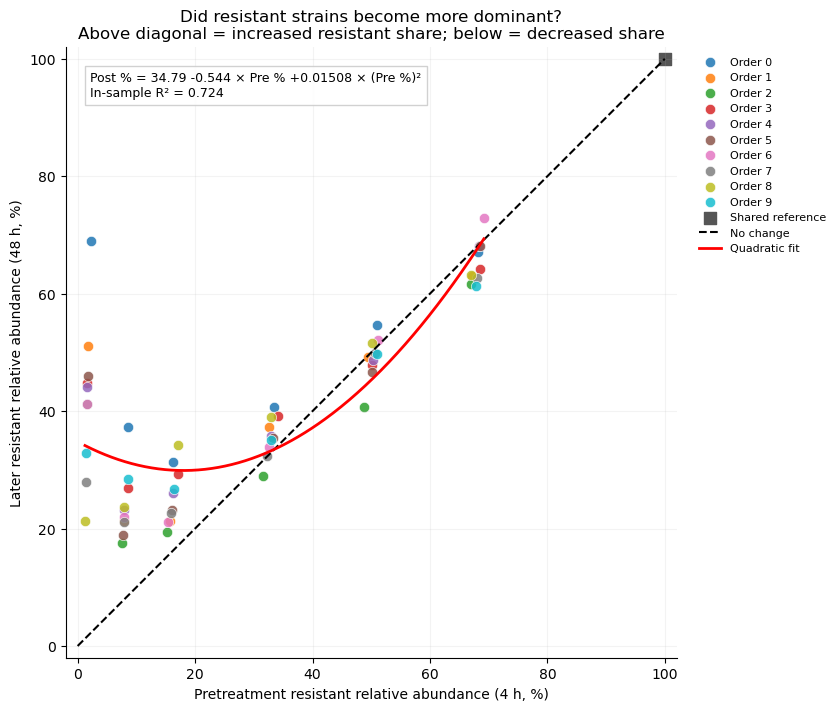

,scenario,order_id,reference,n_resistant,pre_resistant_percent,post_resistant_percent,change_percentage_points,post_biomass_OD,extinct
0,order00_k01,0,False,1,2.252,68.901,66.649,0.942,False
1,order00_k05,0,False,5,8.641,37.279,28.638,0.943,False
2,order00_k10,0,False,10,16.302,31.385,15.083,0.944,False
3,order00_k20,0,False,20,33.396,40.644,7.249,0.944,False
4,order00_k30,0,False,30,50.986,54.661,3.675,0.944,False
...,...,...,...,...,...,...,...,...,...
57,order09_k20,9,False,20,33.000,35.083,2.083,0.944,False
58,order09_k30,9,False,30,50.901,49.752,-1.149,0.944,False
59,order09_k40,9,False,40,67.912,61.374,-6.538,0.944,False
60,reference_k00,-1,True,0,0.000,NaN,NaN,0.000,True


Extinct communities are omitted from the scatterplot because their resistant percentage is undefined.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PRE_HOUR = 4
POST_HOUR = 48  # Change to 24 for end of treatment, before dilution.

rows = []

for d in design.itertuples():
    sim = RUNS[(d.scenario, True)]
    carrier = np.asarray(sim["carrier"], dtype=bool)

    pre = sim["N"][v_sample(sim, PRE_HOUR)]
    post = sim["N"][v_sample(sim, POST_HOUR)]

    pre_percent = (
        100 * pre[carrier].sum() / pre.sum()
        if pre.sum() > 0 else np.nan
    )
    post_percent = (
        100 * post[carrier].sum() / post.sum()
        if post.sum() > 0 else np.nan
    )

    rows.append({
        "scenario": d.scenario,
        "order_id": d.order_id,
        "reference": d.reference,
        "n_resistant": d.n_resistant,
        "pre_resistant_percent": pre_percent,
        "post_resistant_percent": post_percent,
        "change_percentage_points": post_percent - pre_percent,
        "post_biomass_OD": float(post.sum()),
        "extinct": post.sum() <= 0
    })

resistance_shift = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")

orders = sorted(
    resistance_shift.loc[~resistance_shift.reference, "order_id"].unique()
)

for i, order in enumerate(orders):
    group = resistance_shift[
        resistance_shift.order_id.eq(order)
        & ~resistance_shift.extinct
    ]

    ax.scatter(
        group.pre_resistant_percent,
        group.post_resistant_percent,
        color=plt.get_cmap("tab10")(i % 10),
        label=f"Order {order}",
        s=55, alpha=0.85,
        edgecolor="white", linewidth=0.5
    )

references = resistance_shift[
    resistance_shift.reference & ~resistance_shift.extinct
]
ax.scatter(
    references.pre_resistant_percent,
    references.post_resistant_percent,
    color="#555555", marker="s", s=65,
    label="Shared reference"
)

ax.plot(
    [0, 100], [0, 100],
    "k--", linewidth=1.5,
    label="No change"
)

ax.set(
    xlabel=f"Pretreatment resistant relative abundance ({PRE_HOUR} h, %)",
    ylabel=f"Later resistant relative abundance ({POST_HOUR} h, %)",
    title=(
        "Did resistant strains become more dominant?\n"
        "Above diagonal = increased resistant share; below = decreased share"
    ),
    xlim=(-2, 102), ylim=(-2, 102),
    xticks=np.arange(0, 101, 20),
    yticks=np.arange(0, 101, 20)
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.15)
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left", frameon=False, fontsize=8
)


# Fit intermediate configurations, excluding shared references.
fit_data = resistance_shift[
    ~resistance_shift.reference
    & np.isfinite(resistance_shift.pre_resistant_percent)
    & np.isfinite(resistance_shift.post_resistant_percent)
]

x = fit_data.pre_resistant_percent.to_numpy(float)
y = fit_data.post_resistant_percent.to_numpy(float)

if len(x) >= 4 and len(np.unique(x)) >= 3:
    # Scale internally for numerical stability.
    z = x / 100
    coefficients = np.polyfit(z, y, 2)

    x_line = np.linspace(x.min(), x.max(), 300)
    y_line = np.polyval(coefficients, x_line / 100)

    ax.plot(
        x_line, y_line,
        color="red", linewidth=2,
        label="Quadratic fit"
    )

    predicted = np.polyval(coefficients, z)
    total_variation = np.sum((y - y.mean()) ** 2)
    r_squared = (
        1 - np.sum((y - predicted) ** 2) / total_variation
        if total_variation > 0 else np.nan
    )

    # Express the equation using percentages, matching the graph.
    c = coefficients[0] / 10000
    b = coefficients[1] / 100
    a = coefficients[2]

    ax.text(
        0.04, 0.96,
        f"Post % = {a:.2f} {b:+.3f} × Pre % {c:+.5f} × (Pre %)²\n"
        f"In-sample R² = {r_squared:.3f}",
        transform=ax.transAxes,
        va="top", fontsize=9,
        bbox=dict(
            facecolor="white", alpha=0.9,
            edgecolor="#cccccc"
        )
    )

    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left", frameon=False, fontsize=8
    )
else:
    print("Not enough distinct observations for a quadratic fit.")

plt.show()
display(resistance_shift.round(3))

if resistance_shift.extinct.any():
    print(
        "Extinct communities are omitted from the scatterplot because "
        "their resistant percentage is undefined."
    )

,mean_BC_contribution,mean_relative_shift,mean_adjusted_shift,mean_excess_contribution,intrinsic_growth,ic50,carrier_frequency,n_configurations
strain,,,,,,,,
k31,0.03312,0.06624,0.00317,0.00159,0.65053,3.94790,0.28333,60
k19,0.00946,0.01862,0.01158,0.00589,0.58810,6.34570,0.43333,60
k48,0.00923,0.01175,0.01330,0.00790,0.55813,2.03583,0.38333,60
k23,0.00762,0.01426,0.00025,0.00062,0.60448,3.15155,0.46667,60
k36,0.00664,0.01193,-0.00128,0.00004,0.59998,2.90993,0.38333,60
k53,0.00651,-0.00635,0.00257,0.00205,0.48801,1.16802,0.20000,60
k14,0.00633,0.01025,-0.00454,-0.00107,0.59990,1.60233,0.28333,60
k34,0.00601,-0.00281,0.00505,0.00208,0.51375,6.23518,0.43333,60
k32,0.00577,-0.00082,0.00523,0.00274,0.53074,5.47921,0.35000,60


Excluded because composition was undefined: ['reference_k00']


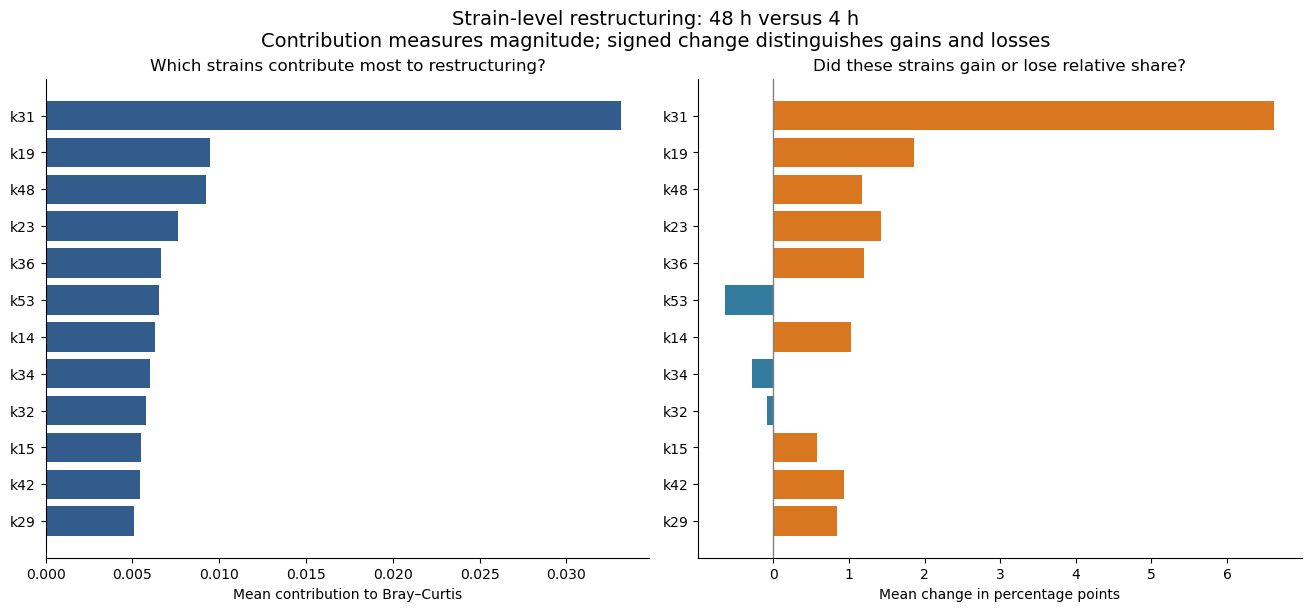

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASELINE_HOUR = 4
ENDPOINT_HOUR = 48

strain_tables = []
excluded_configurations = []

for d in design.itertuples():
    treated = RUNS[(d.scenario, True)]
    control = RUNS[(d.scenario, False)]

    t0 = treated["N"][v_sample(treated, BASELINE_HOUR)]
    t1 = treated["N"][v_sample(treated, ENDPOINT_HOUR)]
    c0 = control["N"][v_sample(control, BASELINE_HOUR)]
    c1 = control["N"][v_sample(control, ENDPOINT_HOUR)]

    if min(t0.sum(), t1.sum(), c0.sum(), c1.sum()) <= 0:
        excluded_configurations.append(d.scenario)
        continue

    carrier = np.asarray(treated["carrier"], dtype=bool)

    # Changes in relative abundance.
    treated_shift = t1 / t1.sum() - t0 / t0.sum()
    control_shift = c1 / c1.sum() - c0 / c0.sum()

    treated_contribution = 0.5 * abs(treated_shift)
    control_contribution = 0.5 * abs(control_shift)

    # Recover intrinsic growth before the carrier's growth penalty.
    intrinsic_growth = (
        treated["mu"] / (1 - BASE.resistance_cost * carrier)
    )

    strain_tables.append(pd.DataFrame({
        "strain": [f"k{i:02d}" for i in range(1, 58)],
        "scenario": d.scenario,
        "order_id": d.order_id,
        "n_resistant": d.n_resistant,
        "reference": d.reference,
        "carrier": carrier,

        "intrinsic_growth": intrinsic_growth,
        "effective_growth": treated["mu"],
        "ic50": treated["ic50"],

        "baseline_relative": t0 / t0.sum(),
        "endpoint_relative": t1 / t1.sum(),
        "baseline_absolute": t0,
        "endpoint_absolute": t1,
        "untreated_endpoint_absolute": c1,

        "absolute_shift": t1 - t0,
        "relative_shift": treated_shift,
        "BC_contribution": treated_contribution,

        "control_relative_shift": control_shift,
        "control_BC_contribution": control_contribution,

        # Positive: a greater relative gain under treatment than control.
        "adjusted_relative_shift": treated_shift - control_shift,

        # Positive: a larger contribution to displacement under treatment.
        "excess_BC_contribution": (
            treated_contribution - control_contribution
        )
    }))

strain_changes = pd.concat(strain_tables, ignore_index=True)

# Rank using intermediate configurations.
# Shared zero/all-resistant references are not repeated observations.
analysis_data = strain_changes[~strain_changes.reference].copy()

strain_ranking = (
    analysis_data.groupby("strain")
    .agg(
        mean_BC_contribution=("BC_contribution", "mean"),
        mean_relative_shift=("relative_shift", "mean"),
        mean_adjusted_shift=("adjusted_relative_shift", "mean"),
        mean_excess_contribution=("excess_BC_contribution", "mean"),
        intrinsic_growth=("intrinsic_growth", "mean"),
        ic50=("ic50", "mean"),
        carrier_frequency=("carrier", "mean"),
        n_configurations=("scenario", "nunique")
    )
    .sort_values("mean_BC_contribution", ascending=False)
)

display(strain_ranking.round(5))
print("Excluded because composition was undefined:", excluded_configurations)

# Show the 12 largest contributors.
top = strain_ranking.head(12).iloc[::-1]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 6), layout="constrained"
)

axes[0].barh(
    top.index, top.mean_BC_contribution,
    color="#315c8b"
)
axes[0].set(
    title="Which strains contribute most to restructuring?",
    xlabel="Mean contribution to Bray–Curtis"
)

colors = np.where(
    top.mean_relative_shift >= 0, "#d97720", "#327a9e"
)
axes[1].barh(
    top.index, 100 * top.mean_relative_shift,
    color=colors
)
axes[1].axvline(0, color="gray", linewidth=1)
axes[1].set(
    title="Did these strains gain or lose relative share?",
    xlabel="Mean change in percentage points"
)

fig.suptitle(
    f"Strain-level restructuring: {ENDPOINT_HOUR} h versus {BASELINE_HOUR} h\n"
    "Contribution measures magnitude; signed change distinguishes gains and losses",
    fontsize=14
)
plt.show()

,mean_adjusted_shift_S,mean_adjusted_shift_R,n_S,n_R,R_minus_S,intrinsic_growth,ic50
strain,,,,,,,
k31,-0.01563,0.02878,7.0,3.0,0.04441,0.65053,3.94790
k23,-0.00755,0.01249,6.0,4.0,0.02004,0.60448,3.15155
k14,-0.00859,0.01126,7.0,3.0,0.01984,0.59990,1.60233
k36,-0.00700,0.01129,5.0,5.0,0.01829,0.59998,2.90993
k04,-0.00765,0.00931,6.0,4.0,0.01696,0.59102,1.20494
k11,-0.00573,0.00918,5.0,5.0,0.01491,0.58814,2.83146
k41,-0.00591,0.00831,6.0,4.0,0.01423,0.58178,1.94715
k49,-0.00441,0.00761,7.0,3.0,0.01202,0.57880,3.38933
k19,-0.00307,0.00877,6.0,4.0,0.01183,0.58810,6.34570


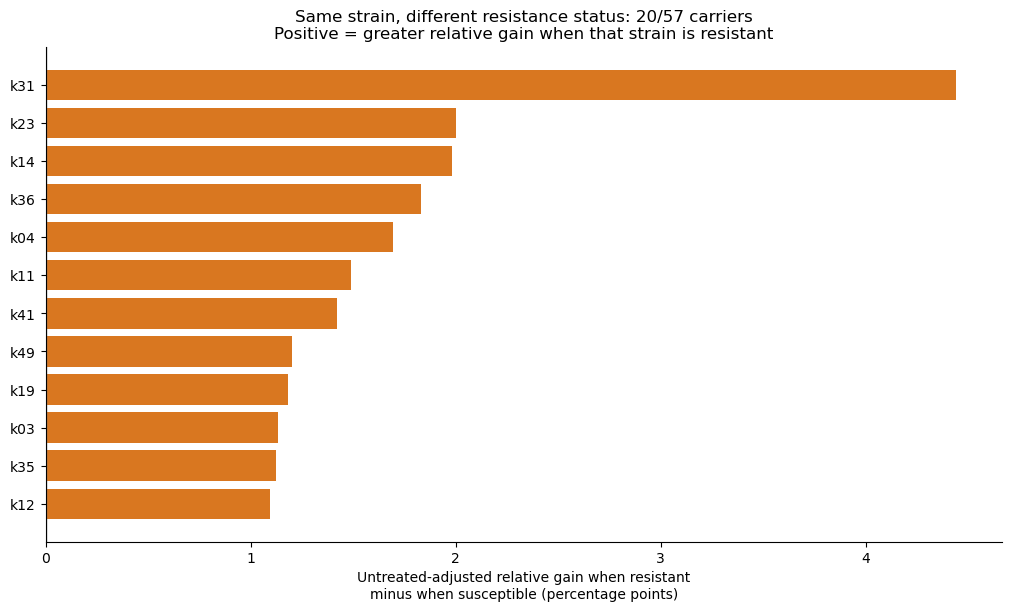

In [31]:
RESISTANT_COUNT = 20
MIN_CONFIGURATIONS_PER_STATUS = 2

selected = analysis_data[
    analysis_data.n_resistant.eq(RESISTANT_COUNT)
]

status_comparison = (
    selected.groupby(["strain", "carrier"])
    .agg(
        mean_adjusted_shift=("adjusted_relative_shift", "mean"),
        n=("scenario", "size")
    )
    .unstack("carrier")
)

status_comparison.columns = [
    f"{metric}_{'R' if resistant else 'S'}"
    for metric, resistant in status_comparison.columns
]

required = {
    "mean_adjusted_shift_R", "mean_adjusted_shift_S",
    "n_R", "n_S"
}

if not required.issubset(status_comparison.columns):
    print("Choose a resistance count with both carrier and susceptible observations.")
else:
    status_comparison = status_comparison[
        status_comparison.n_R.ge(MIN_CONFIGURATIONS_PER_STATUS)
        & status_comparison.n_S.ge(MIN_CONFIGURATIONS_PER_STATUS)
    ].copy()

    status_comparison["R_minus_S"] = (
        status_comparison.mean_adjusted_shift_R
        - status_comparison.mean_adjusted_shift_S
    )

    status_comparison = status_comparison.join(
        strain_ranking[["intrinsic_growth", "ic50"]]
    )

    display(
        status_comparison.sort_values(
            "R_minus_S", ascending=False
        ).round(5)
    )

    if status_comparison.empty:
        print("Too few configurations per status; try another carrier count.")
    else:
        largest = (
            status_comparison.R_minus_S.abs()
            .nlargest(12).index
        )
        shown = (
            status_comparison.loc[largest]
            .sort_values("R_minus_S")
        )

        fig, ax = plt.subplots(
            figsize=(10, 6), layout="constrained"
        )

        ax.barh(
            shown.index,
            100 * shown.R_minus_S,
            color=np.where(
                shown.R_minus_S >= 0, "#d97720", "#327a9e"
            )
        )
        ax.axvline(0, color="gray", linewidth=1)

        ax.set(
            xlabel=(
                "Untreated-adjusted relative gain when resistant\n"
                "minus when susceptible (percentage points)"
            ),
            title=(
                f"Same strain, different resistance status: "
                f"{RESISTANT_COUNT}/57 carriers\n"
                "Positive = greater relative gain when that strain is resistant"
            )
        )
        plt.show()

In [32]:
import numpy as np
import pandas as pd

TOP_N = 12

# Establish each strain's growth rank across all 57 strains.
growth_reference = (
    strain_changes.groupby("strain")
    .agg(intrinsic_growth=("intrinsic_growth", "first"))
)

growth_reference["growth_rank"] = (
    growth_reference.intrinsic_growth
    .rank(ascending=False, method="min")
    .astype(int)
)

community_mean_growth = growth_reference.intrinsic_growth.mean()

growth_reference["growth_vs_average_percent"] = (
    100 * (
        growth_reference.intrinsic_growth / community_mean_growth - 1
    )
)

# Identify the largest average contributors to restructuring.
top_names = strain_ranking.head(TOP_N).index

# Separate results according to whether each strain was resistant.
profiles = (
    analysis_data[analysis_data.strain.isin(top_names)]
    .groupby(["strain", "carrier"])
    .agg(
        n_configurations=("scenario", "nunique"),
        effective_growth=("effective_growth", "mean"),
        mean_BC_contribution=("BC_contribution", "mean"),
        mean_baseline_share=("baseline_relative", "mean"),
        mean_endpoint_share=("endpoint_relative", "mean"),
        mean_relative_shift=("relative_shift", "mean")
    )
    .reset_index()
    .merge(growth_reference.reset_index(), on="strain")
)

profiles["status"] = np.where(
    profiles.carrier, "Resistant", "Susceptible"
)

profiles["baseline_share_percent"] = 100 * profiles.mean_baseline_share
profiles["endpoint_share_percent"] = 100 * profiles.mean_endpoint_share
profiles["change_percentage_points"] = 100 * profiles.mean_relative_shift

# Order strains by their overall restructuring contribution.
profiles["restructuring_rank"] = (
    profiles.strain.map(
        {name: rank + 1 for rank, name in enumerate(top_names)}
    )
)

profiles = profiles.sort_values(
    ["restructuring_rank", "status"]
)

display(
    profiles[[
        "strain",
        "status",
        "n_configurations",
        "growth_rank",
        "intrinsic_growth",
        "effective_growth",
        "growth_vs_average_percent",
        "mean_BC_contribution",
        "baseline_share_percent",
        "endpoint_share_percent",
        "change_percentage_points"
    ]].round(4)
)

print(
    f"Mean intrinsic growth rate across all 57 strains: "
    f"{community_mean_growth:.4f} per hour"
)

# Plain-English summaries.
for name in top_names:
    reference = growth_reference.loc[name]
    comparison = reference.growth_vs_average_percent

    direction = "faster" if comparison >= 0 else "slower"

    print(
        f"\n{name}: growth rank {int(reference.growth_rank)}/57 "
        f"(1 = fastest); {abs(comparison):.1f}% {direction} "
        f"than the community average."
    )

    for row in profiles[profiles.strain.eq(name)].itertuples():
        print(
            f"  When {row.status.lower()} "
            f"({row.n_configurations} configurations): "
            f"effective maximum growth = {row.effective_growth:.4f}/h; "
            f"average share changed from "
            f"{row.baseline_share_percent:.2f}% to "
            f"{row.endpoint_share_percent:.2f}%."
        )

,strain,status,n_configurations,growth_rank,intrinsic_growth,effective_growth,growth_vs_average_percent,mean_BC_contribution,baseline_share_percent,endpoint_share_percent,change_percentage_points
11,k31,Resistant,17,1,0.6505,0.6180,18.0555,0.0528,2.3594,12.9163,10.5568
10,k31,Susceptible,43,1,0.6505,0.6505,18.0555,0.0253,2.6077,7.6775,5.0698
5,k19,Resistant,26,7,0.5881,0.5587,6.7255,0.0168,1.8745,5.2431,3.3685
4,k19,Susceptible,34,7,0.5881,0.5881,6.7255,0.0038,2.0497,2.7605,0.7108
21,k48,Resistant,23,26,0.5581,0.5302,1.2867,0.0201,1.6747,5.5314,3.8567
20,k48,Susceptible,37,26,0.5581,0.5581,1.2867,0.0025,1.8371,1.3456,-0.4916
7,k23,Resistant,28,2,0.6045,0.5743,9.6993,0.0110,2.0021,4.2118,2.2096
6,k23,Susceptible,32,2,0.6045,0.6045,9.6993,0.0046,2.1657,2.9056,0.7399
17,k36,Resistant,23,3,0.6000,0.5700,8.8825,0.0101,1.9625,3.9733,2.0108
16,k36,Susceptible,37,3,0.6000,0.6000,8.8825,0.0045,2.1447,2.8296,0.6850


Mean intrinsic growth rate across all 57 strains: 0.5510 per hour

k31: growth rank 1/57 (1 = fastest); 18.1% faster than the community average.
  When resistant (17 configurations): effective maximum growth = 0.6180/h; average share changed from 2.36% to 12.92%.
  When susceptible (43 configurations): effective maximum growth = 0.6505/h; average share changed from 2.61% to 7.68%.

k19: growth rank 7/57 (1 = fastest); 6.7% faster than the community average.
  When resistant (26 configurations): effective maximum growth = 0.5587/h; average share changed from 1.87% to 5.24%.
  When susceptible (34 configurations): effective maximum growth = 0.5881/h; average share changed from 2.05% to 2.76%.

k48: growth rank 26/57 (1 = fastest); 1.3% faster than the community average.
  When resistant (23 configurations): effective maximum growth = 0.5302/h; average share changed from 1.67% to 5.53%.
  When susceptible (37 configurations): effective maximum growth = 0.5581/h; average share changed from

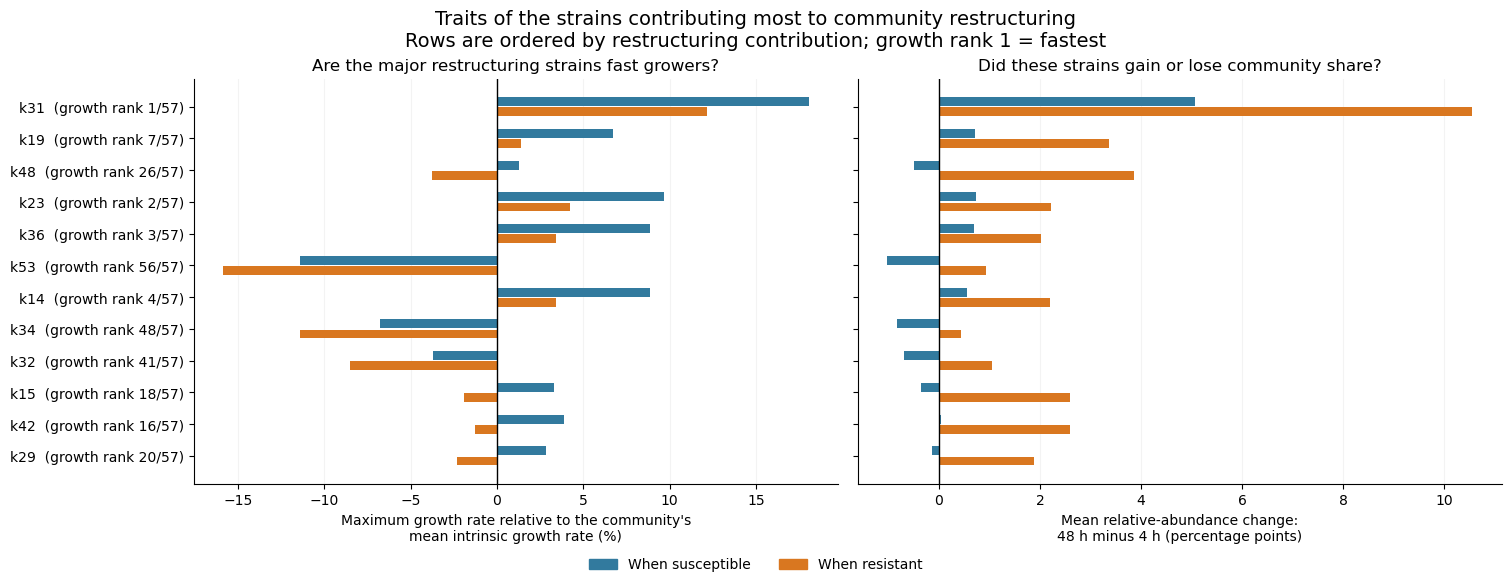

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Preserve the ranking: largest restructuring contributor first.
names = list(top_names)
y = np.arange(len(names))

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, max(5, len(names) * 0.48)),
    sharey=True,
    layout="constrained"
)

# LEFT: maximum growth rates relative to the community mean.
for status, offset, color in [
    ("Susceptible", -0.16, "#327a9e"),
    ("Resistant", 0.16, "#d97720")
]:
    data = (
        profiles[profiles.status.eq(status)]
        .set_index("strain")
        .reindex(names)
    )

    relative_growth = (
        100 * (data.effective_growth / community_mean_growth - 1)
    )

    axes[0].barh(
        y + offset,
        relative_growth,
        height=0.28,
        color=color
    )

axes[0].axvline(0, color="black", linewidth=1)
axes[0].set(
    title="Are the major restructuring strains fast growers?",
    xlabel=(
        "Maximum growth rate relative to the community's\n"
        "mean intrinsic growth rate (%)"
    )
)
axes[0].grid(axis="x", alpha=0.15)
axes[0].set_axisbelow(True)

# Include the intrinsic growth rank beside each strain.
labels = [
    f"{name}  (growth rank "
    f"{int(growth_reference.loc[name, 'growth_rank'])}/57)"
    for name in names
]

axes[0].set_yticks(y, labels)
axes[0].invert_yaxis()

# RIGHT: change in relative abundance, separated by carrier status.
for status, offset, color in [
    ("Susceptible", -0.16, "#327a9e"),
    ("Resistant", 0.16, "#d97720")
]:
    data = (
        profiles[profiles.status.eq(status)]
        .set_index("strain")
        .reindex(names)
    )

    axes[1].barh(
        y + offset,
        data.change_percentage_points,
        height=0.28,
        color=color
    )

axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(
    title="Did these strains gain or lose community share?",
    xlabel=(
        f"Mean relative-abundance change:\n"
        f"{ENDPOINT_HOUR} h minus {BASELINE_HOUR} h "
        "(percentage points)"
    )
)
axes[1].grid(axis="x", alpha=0.15)
axes[1].set_axisbelow(True)

fig.legend(
    handles=[
        Patch(color="#327a9e", label="When susceptible"),
        Patch(color="#d97720", label="When resistant")
    ],
    loc="outside lower center",
    ncol=2, frameon=False
)

fig.suptitle(
    "Traits of the strains contributing most to community restructuring\n"
    "Rows are ordered by restructuring contribution; growth rank 1 = fastest",
    fontsize=14
)

plt.show()

## Saved files and how to reproduce the results

- `fixed_strain_traits.csv`: the same intrinsic properties used in every design.
- `experiment_design.csv` and `carrier_assignments.csv`: exact carrier identities for every count/order.
- `simulation_audit.csv`: checks on actual simulated initialization and numerical balance.
- `all_timepoint_outcomes.csv`: baseline predictor and raw/adjusted responses at 6, 24, 48 h.
- `strain_sampling_timepoints.csv.gz`: absolute and relative strain abundances at 0, 4, 6, 24, 48 h; 24 h is pre-transfer.
- `timepoint_correlations.csv`: pooled Spearman estimates, assignment-order intervals, log-x Pearson estimates and valid sample sizes.
- `correlations_within_each_assignment_order.csv`: within-order association estimates.
- `extinction_and_missing_outcomes.csv`: outcomes absent from diversity/composition correlations.
- `outcome_summary_by_count_time.csv`: descriptive summaries across carrier orders.
- `cache/`: compressed full simulation trajectories, including both sides of the transfer jump. Each file contains `t`, `N`, `R`, `a`, `carrier`, `mu`, `ic50` and transfer diagnostics. `settings.json` records the source hash and settings.
- `figures/`: PNG versions of the figures shown here.

Run all cells in order. Existing matching simulations are reused; metrics and figures are recalculated. To sample more carrier identities, increase `N_ORDERS` and Run All. To force numerical reruns, set `RECOMPUTE=True`. To explore a different intrinsic community or dose, change `TRAIT_SEED` or `DOSE`, then Run All; the cache distinguishes those settings. Those changes answer a broader robustness question than the fixed-community analysis above.
